# AnalyzeTCSPC — tiled XYTZ
TCSPC-FLIM analysis for single-file ISS Vista exports of an Olympus MATL tile grid (`..._Decay<nbin>_<nx>x<ny>_Z<tiles·z>_...tif`).
**Step 0** converts the raw float32 file to uint8 tiles, registers the tiles and writes a stitched TCSPC volume (one TYX TIFF per z), plus the Olympus PMT channel (e.g. mCherry) stitched with the same tile positions when its `.oir` tiles are present; Steps 1–16 are the `AnalyzeTCSPC.ipynb` pipeline run on that volume. Time series (repeated z-stacks): `AnalyzeTCSPC_XYTZTime.ipynb`.

Run cells **in order**. Edit the **Step 0a** cell for each experiment.

In [ ]:
import os
os.environ['KMP_DUPLICATE_LIB_OK'] = 'TRUE'   # prevent OpenMP conflict between MKL and torch on Windows

import torch   # must be imported before numpy/scipy to avoid OpenMP runtime clash

import sys
import csv
import json
import glob
import re
import warnings
import importlib
import tkinter as tk
from tkinter import filedialog
from collections import defaultdict

from datetime import datetime
import numpy as np
import matplotlib.pyplot as plt
import tifffile
import pandas as pd
from scipy.ndimage import median_filter, gaussian_filter
from skimage.restoration import (denoise_bilateral,
                                  denoise_nl_means as _nlm_fn,
                                  rolling_ball as _rolling_ball_fn,
                                  estimate_sigma as _esig_fn)
from imageio import imwrite
from cellpose import models as _cp_models

sys.path.insert(0, 'X:/FLIM_2026')
import FastFLIM_mod_AT0 as _ffm_module
from FastFLIM_mod_AT0 import FastFLIM_mod_AT0
from flim_helpers import uplowthresh, Fit_decay, Calc_Phasor_Mat, phasor_ref_correction, read_fbs_metadata
import multiday as md

print(f'torch {torch.__version__}  CUDA {torch.version.cuda}  GPU available: {torch.cuda.is_available()}')

## Helper functions
`uplowthresh` finds upper/lower display thresholds from the pixel histogram.
`Fit_decay` fits a multi-exponential model to the spatially-averaged decay.
`Calc_Phasor_Mat` computes phasor components and the density matrix.

## Step 0: Tiled XYTZ acquisition → uint8 tiles → registration → stitched TCSPC
- **Acquisition folder** (`acq_path`, folder picker): the raw float32 Vista TIFF in it is the `.tif` named
  `<name>_Decay<n>_<nx>x<ny>_Z<n>_Ch1_T1_P1_S1.tif` (`vt.find_raw`). With `delete_raw_after_convert = True` (default),
  0b deletes it once the uint8 tiles hold all of its photons (`vt.delete_raw_if_lossless`): no count clipped at 255,
  at most a few bins that are not photon counts (2 in every file so far), and every tile file, read back, gives the
  photon counts per z-block and bin recorded during the conversion. The uint8 tiles are ~1/4 of the raw size
  (Slice3: 9.7 GB → 2.4 GB). Without the raw file its name comes from the conversion report, and Steps 0–17 run from the
  uint8 tiles; only `rerun_convert = True` then fails. The `.fbs.xml` and the Olympus files stay.
- **0a** parameters & metadata. Bins, tile size and number of z-blocks come from the Vista file name (`_Decay128`,
  `_512x512`, `_Z210`). Read automatically when present, otherwise the defaults in the cell are used (printed):
  - tile grid (max `yIndex`/`xIndex` + 1), overlap and acquisition order ← Olympus `matl.omp2info`
    (searched below the raw file's folder);
  - voxel size (xy pixel, z step) ← the Olympus `.oir` tiles;
  - laser period `Tcycle` ← `TacTimeRange` in the ISS `<name>.fbs.xml` next to the raw file, checked against the
    laser frequency.
- **0b** float32 → uint8: one ImageJ hyperstack per tile (`ZCYX`, decay bins as channels) in `tiles_uint8/`, in the
  file's block order. Vista writes classic TIFFs past 4 GB: pages after ~4 GB have no IFD, and their IFDs are written
  over plane data in the first 4 GB. Those pixels are located exactly and zeroed (reported as *corrupted bins*).
  **Dropped planes:** Vista can miss planes the microscope acquired; every later block then sits in a slot too early
  and the last blocks of the file stay empty. With Olympus tiles (same scan, complete), every block is matched to the
  Olympus frame it shows and moved to its true tile / z (`<base>_block_map.json`); planes never recorded stay empty
  (no photons, coverage 0) and a block straddling a gap is discarded. A warning lists the missing planes. Without
  Olympus tiles, empty blocks only trigger a warning (the stitch is then unreliable).
- **0c** registration: masked normalised cross-correlation on neighbour overlaps → integer (dz, dy, dx) per tile,
  global least squares. The tile order is the acquisition order from `matl.omp2info`; without it,
  `tile_layout='auto'` scores raster/snake × start corner (and the transposed grid) and `tile_layout_fallback` is
  used when nothing matches or it ties with the best. `max_dz` bounds the z offset between neighbours: with a tilted
  objective, neighbouring tiles are several planes apart (2026-11-06: 3–10 planes); a pair at the bound gives a
  warning. `tile_reg_source='auto'` registers on the Olympus PMT channel when its tiles exist (complete, no diffuse
  background; same scan, so the positions apply to both), otherwise on the time-projected FLIM intensity. Positions are recomputed when a registration setting or
  the block assignment of 0b changes.
- **0d** stitching: TCSPC overlaps are **summed** (raw counts, more photons per decay) → `stitched/` (= `data_folder`
  for Steps 1–16). Segmentation intensity is per-tile normalised and feather-blended → `<base>_stitched_intensity.tif`
  (used by Step 2 instead of summing `data_paths`, so overlaps are not double-counted).
- **0e** Olympus PMT channel (e.g. mCherry, red light sent to the Olympus PMT by the beamsplitter): the `.oir` tiles
  are read, their pixel offset to the TCSPC tiles is measured (same scan, two detectors) and corrected, and they are
  stitched with the **same tile positions** as 0c → `<base>_stitched_<CH>.tif`, the default segmentation input of Step 2.

Outputs are reused when present; set `rerun_convert / rerun_register / rerun_fuse / rerun_oir` to redo a step
(re-registering re-stitches automatically). Tile offsets: `<base>_tile_positions.json`.


In [ ]:
# ── Step 0a: tiled acquisition parameters ─────────────────────────────────────
import vista_tiles as vt
import olympus_oir as oo
importlib.reload(vt)
importlib.reload(oo)

def _pick_acq_dir():
    root = tk.Tk(); root.withdraw(); root.attributes('-topmost', True)
    p = filedialog.askdirectory(title='Select the acquisition folder (raw Vista TIFF, .fbs.xml, Olympus/)')
    root.destroy()
    return p or None

# ── acquisition folder (or the raw .tif itself) — swap comments for hardcoded / interactive ──
acq_path = r"D:\Peredox_FLIM\XYZTTile1_336_X0.4Y-2.8_Decay128_512x512_Z210_Ch1_T1_P1_S1"
# acq_path = _pick_acq_dir()
if not acq_path:
    raise RuntimeError('No acquisition folder selected.')
# the raw float32 Vista TIFF in that folder; once it was deleted after its uint8 conversion (delete_raw_after_convert),
# its name comes from the conversion report in tiles_uint8/ and Step 0b uses the uint8 tiles
raw_path, raw_exists = vt.find_raw(acq_path)

# ── defaults: used only where the metadata read below are missing ─────────────
tile_grid    = (3, 2)    # (rows, cols)                <- matl.omp2info; (1, 1) = single position
tile_overlap = 0.20      # nominal fractional overlap  <- matl.omp2info (the true step is measured)
xy_pixel_um  = 0.99      # XY pixel size in µm          <- Olympus .oir
z_step_um    = 3.0       # Z step in µm                 <- Olympus .oir
Tcycle       = 12.5      # laser period in ns (80 MHz)  <- TacTimeRange in the ISS .fbs.xml

# ── tile registration ─────────────────────────────────────────────────────────
tile_layout          = 'auto'       # 'auto': acquisition order from matl.omp2info, else detected from the
                                    #  overlaps (also tests the transposed grid); or one of vt.LAYOUTS
tile_layout_fallback = 'snake_tl'   # detection only: used when nothing matches or it ties with the best
tile_shape_px        = None         # (ny, nx) per tile; None = from file name '_<nx>x<ny>_'
max_dz               = 12           # max z offset between neighbouring tiles (planes); a tilted objective
                                    #  puts neighbours several planes apart (2026-11-06: 3-10 planes)
tile_reg_source      = 'auto'       # 'auto' = Olympus PMT channel if its tiles exist, else 'flim'; or 'flim' / 'olympus'

# ── Olympus multi-area folder: matl.omp2info + one .oir per tile ──────────────
olympus_dir = 'auto'     # 'auto' = search below the raw file's folder; or a path; None = ignore
oir_channel = 'auto'     # Step 0e channel: 'auto' = red emission filter (else brightest), or a name, e.g. 'CH1'

rerun_convert  = False
rerun_register = False
rerun_fuse     = False
delete_raw_after_convert = True   # Step 0b: delete the float32 raw TIFF (~4x the size of its uint8 tiles) once the tiles
                                  # are verified to hold all of its photons (no count clipped at 255; every tile read back)

# ── derived ───────────────────────────────────────────────────────────────────
vista_info = vt.parse_vista_name(raw_path)
if tile_shape_px is not None and tuple(tile_shape_px) != (vista_info['ny'], vista_info['nx']):
    raise ValueError(f'tile_shape_px {tile_shape_px} != file name {vista_info["ny"]}x{vista_info["nx"]}')
raw_dir   = os.path.dirname(raw_path)
tiles_dir = os.path.join(raw_dir, 'tiles_uint8')
pos_json  = os.path.join(raw_dir, f'{vista_info["base"]}_tile_positions.json')
print(f'Raw file: {raw_path}  ' + (f'({os.path.getsize(raw_path) / 1e9:.1f} GB)' if raw_exists else
      '(deleted after its uint8 conversion: Step 0b uses the uint8 tiles)'))

# tile layout <- Olympus multi-area protocol
matl_info = None
if olympus_dir == 'auto':
    olympus_dir = oo.find_matl_dir(raw_dir)
if olympus_dir:
    matl_info = oo.read_matl_info(olympus_dir)
    tile_grid = matl_info['grid']
    tile_overlap = matl_info['overlap'] if matl_info['overlap'] is not None else tile_overlap
    _rc = ' '.join(f'({r},{c})' for r, c in matl_info['grid_rc'])
    print(f'Tile config  <- matl.omp2info  ({os.path.relpath(olympus_dir, raw_dir)})')
    print(f'  grid {tile_grid[0]} rows x {tile_grid[1]} cols  |  overlap {tile_overlap:.0%}  |  '
          f'acquisition order {matl_info["layout"] or "not a standard layout"}  (row,col): {_rc}')
else:
    print(f'Tile config  <- DEFAULTS (no matl.omp2info below the raw folder)')
    print(f'  grid {tile_grid[0]} rows x {tile_grid[1]} cols  |  overlap {tile_overlap:.0%}  |  '
          f'layout {"detected from the overlaps" if tile_layout == "auto" else tile_layout}')
_reg_layout = (matl_info['layout'] if tile_layout == 'auto' and matl_info and matl_info['layout']
               else tile_layout)
n_tiles  = tile_grid[0] * tile_grid[1]
if vista_info['n_blocks'] % n_tiles:
    raise ValueError(f'_Z{vista_info["n_blocks"]} is not a multiple of {n_tiles} tiles ({tile_grid[0]}x{tile_grid[1]} '
                     f'grid{"" if matl_info else ", default"}): set tile_grid = (1, 1) for a single position; a time series goes to AnalyzeTCSPC_XYTZTime.ipynb')
n_z_tile = vista_info['n_blocks'] // n_tiles
print(f'  {vista_info["nbin"]} bins  |  tile {vista_info["ny"]}x{vista_info["nx"]} px  |  '
      f'{vista_info["n_blocks"]} z-blocks = {n_tiles} tiles x {n_z_tile} z')

# voxel size <- Olympus .oir metadata (the ISS .fbs.xml ImageRegion is a placeholder)
oir_meta, oir_ch = None, None
_oir0 = next((f for f in matl_info['files'] if f), None) if matl_info else None
if _oir0:
    oir_meta = oo.oir_metadata(_oir0)
    oir_ch   = oo.pick_channel(oir_meta, oir_channel, path=_oir0)
if oir_meta and (oir_meta['n_t'] > 1 or (n_z_tile > oir_meta['n_z'] and n_z_tile % oir_meta['n_z'] == 0)):
    raise ValueError(f'Time-lapse acquisition (Olympus .oir: {max(oir_meta["n_t"], n_z_tile // oir_meta["n_z"])} '
                     f'timepoints of {oir_meta["n_z"]} planes): use AnalyzeTCSPC_XYTZTime.ipynb')
if oir_meta and oir_meta['pixel_um'] and oir_meta['z_step_um']:
    xy_pixel_um, z_step_um = float(oir_meta['pixel_um'][1]), float(oir_meta['z_step_um'])
    print(f'Voxel size   <- Olympus .oir:  xy {xy_pixel_um:.4f} µm  |  z {z_step_um:g} µm  '
          f'({oir_meta["n_z"]} planes per tile)')
    if (oir_meta['n_z'], oir_meta['ny'], oir_meta['nx']) != (n_z_tile, vista_info['ny'], vista_info['nx']):
        print(f'  WARNING: Olympus tiles are {oir_meta["n_z"]}x{oir_meta["ny"]}x{oir_meta["nx"]} (z,y,x), '
              f'Vista tiles {n_z_tile}x{vista_info["ny"]}x{vista_info["nx"]} — check the pairing (Step 0e is skipped)')
else:
    print(f'Voxel size   <- DEFAULTS (no Olympus .oir):  xy {xy_pixel_um} µm  |  z {z_step_um} µm')
if oir_ch:
    _others = ', '.join(f'{c["name"]} ({c["filter"]})' for c in oir_meta['channels'] if c['id'] != oir_ch['id'])
    print(f'Olympus channel for Step 0e: {oir_ch["name"]} ({oir_ch["filter"]}, {oir_ch["voltage"]:g} V)'
          + (f'  |  not used: {_others}' if _others else ''))

# laser period <- TacTimeRange in the ISS .fbs.xml
fbs_xml  = vt.find_fbs_xml(raw_path)
fbs_meta = read_fbs_metadata(fbs_xml) if fbs_xml else None
if fbs_meta and fbs_meta['Tcycle']:
    Tcycle = float(fbs_meta['Tcycle'])
    print(f'Laser period <- TacTimeRange in {os.path.basename(fbs_xml)}:  Tcycle {Tcycle:.4f} ns  '
          f'(dt {Tcycle / vista_info["nbin"]:.4f} ns/bin)')
    if fbs_meta['freq_mhz'] and abs(1000.0 / fbs_meta['freq_mhz'] - Tcycle) > 0.01 * Tcycle:
        warnings.warn(f'TacTimeRange {Tcycle:.4f} ns != laser period {1000.0 / fbs_meta["freq_mhz"]:.4f} ns '
                      f'(MacroTimeClockFrequency): check the Vista acquisition settings', RuntimeWarning)
else:
    print(f'Laser period <- DEFAULT Tcycle {Tcycle} ns  '
          f'({"no TacTimeRange in " + os.path.basename(fbs_xml) if fbs_xml else "no .fbs.xml next to the raw file"})')


In [ ]:
# ── Step 0b: float32 Vista TIFF → uint8 tiles ─────────────────────────────────
conv = vt.convert_to_uint8(raw_path, tiles_dir, n_pos=n_tiles, xy_pixel_um=xy_pixel_um,
                           z_step_um=z_step_um, overwrite=rerun_convert)
tile_int = conv['tile_int']          # (tile, z, y, x) photons summed over bins, file block order
_rep = conv['report']
print(f'Corrupted bins zeroed: {100 * _rep["corrupted_fraction"]:.3f}%  |  '
      f'residual junk: {_rep["residual_junk_pixels"]}  |  clipped >255: {_rep["clipped_pixels"]}  |  '
      f'max count/bin/px: {_rep["max_count"]:g}')

# ── dropped planes: true tile / z of every block, from the Olympus tiles of the same scan ──
_ny, _nx  = tile_int.shape[2:]
_empty    = np.flatnonzero(tile_int.reshape(n_tiles * n_z_tile, -1).max(axis=1) == 0)
blk, oir_tiles = None, None
block_of_slot  = None   # None = file layout; else the file block shown at slot tile*n_z + z (-1 = no data)
if (matl_info and oir_ch and all(matl_info['files'])
        and (oir_meta['n_z'], oir_meta['ny'], oir_meta['nx']) == tuple(tile_int.shape[1:])):
    oir_tiles = np.stack([oo.read_oir_channel(f, oir_ch['id'], oir_meta['n_z'], oir_meta['ny'], oir_meta['nx'])
                          for f in matl_info['files']])
    blk = vt.align_blocks(tile_int.reshape(-1, _ny, _nx), oir_tiles.reshape(-1, _ny, _nx))
    with open(os.path.join(raw_dir, f'{vista_info["base"]}_block_map.json'), 'w') as _f:
        json.dump({k: (v.tolist() if isinstance(v, np.ndarray) else v) for k, v in blk.items() if k != 'ncc_matrix'}, _f)
    _kept = blk['slot_of_block'] >= 0
    print(f'Block check vs Olympus {oir_ch["name"]}: {int(_kept.sum())} of {_kept.size} blocks matched  '
          f'(NCC median {np.nanmedian(blk["ncc"][_kept]):.2f}, min {np.nanmin(blk["ncc"][_kept]):.2f})')
    if blk['shifted'] or blk['missing'].size:
        block_of_slot = blk['block_of_slot']
        _flat = tile_int.reshape(-1, _ny, _nx)
        _true = np.zeros_like(_flat)
        _true[block_of_slot >= 0] = _flat[block_of_slot[block_of_slot >= 0]]
        tile_int = _true.reshape(tile_int.shape)
        _miss = '; '.join(f'tile {t}: z {[int(s % n_z_tile) for s in blk["missing"] if s // n_z_tile == t]}'
                          for t in range(n_tiles) if any(s // n_z_tile == t for s in blk['missing']))
        warnings.warn(f'Vista did not record {blk["missing"].size} of {block_of_slot.size} planes '
                      f'({blk["empty"].size} empty blocks at the end of the file'
                      + (f', {blk["discarded"].size} block(s) straddling a gap discarded: {blk["discarded"].tolist()}'
                         if blk['discarded'].size else '')
                      + '). The recorded blocks were moved to their true tile / z (matched to the Olympus channel); '
                      f'the missing planes stay empty (no photons, coverage 0) -> {_miss}', RuntimeWarning)
    else:
        print('  every block is at its file position: no dropped planes')
elif _empty.size:
    _t0, _z0 = divmod(int(_empty[0]), n_z_tile)
    warnings.warn(f'{_empty.size} of {n_tiles * n_z_tile} empty z-blocks (first: tile {_t0} z {_z0}): Vista recorded '
                  f'fewer planes than the microscope acquired. Blocks after the first dropped plane sit at the wrong '
                  f'tile / z and there are no Olympus tiles to re-assign them: registration and stitching are '
                  f'unreliable.', RuntimeWarning)

_ph = tile_int.sum(axis=(2, 3))
fig, axs = plt.subplots(2, n_tiles, figsize=(max(3.2 * n_tiles, 4.5), 5.2), squeeze=False,
                        gridspec_kw=dict(height_ratios=[3, 1.2]))
for p in range(n_tiles):
    _mp = tile_int[p].max(axis=0)
    axs[0, p].imshow(_mp, cmap='gray', vmax=np.percentile(_mp, 99.5))
    axs[0, p].set_title(f'tile {p}  (max over z)', fontsize=9)
    axs[0, p].axis('off')
    axs[1, p].plot(_ph[p] / 1e3, '.-', lw=0.8)
    if block_of_slot is not None:
        _mz = np.flatnonzero(block_of_slot.reshape(n_tiles, n_z_tile)[p] < 0)
        axs[1, p].plot(_mz, np.zeros(_mz.size), 'rx', ms=5, label='not recorded')
    axs[1, p].set_xlabel('z')
axs[1, 0].set_ylabel('photons / 1e3')
if block_of_slot is not None:
    axs[1, 0].legend(fontsize=7)
plt.suptitle(f'{vista_info["base"]}  —  tiles in acquisition order'
             + ('  (blocks moved to their true tile / z)' if block_of_slot is not None else ''), fontsize=9)
plt.tight_layout()
plt.show()

if blk is not None:   # QC: which Olympus frame each Vista block shows
    _S = blk['ncc_matrix']
    fig, ax = plt.subplots(figsize=(7, 6))
    ax.imshow(_S, aspect='auto', cmap='magma', vmin=0, vmax=0.9, interpolation='nearest')
    ax.plot([0, _S.shape[0] - 1], [0, _S.shape[0] - 1], 'w--', lw=0.6, label='file layout')
    _b = np.flatnonzero(blk['slot_of_block'] >= 0)
    ax.plot(blk['slot_of_block'][_b], _b, 'c.', ms=2, label='assigned tile / z')
    if blk['discarded'].size:
        ax.plot(_S[blk['discarded']].argmax(axis=1), blk['discarded'], 'rx', ms=7, label='discarded (straddles a gap)')
    for t in range(1, n_tiles):
        ax.axvline(t * n_z_tile - 0.5, color='w', lw=0.3)
    ax.set_xlabel(f'Olympus {oir_ch["name"]} frame  (tile x {n_z_tile} + z)')
    ax.set_ylabel('Vista z-block (file order)')
    ax.set_title('NCC: Vista block vs Olympus frame', fontsize=10)
    ax.legend(loc='lower right', fontsize=8)
    plt.tight_layout()
    plt.show()

# ── raw float32 file: deleted once the uint8 tiles hold all of its photons (delete_raw_after_convert, Step 0a) ──
if raw_exists and delete_raw_after_convert:
    _deleted, _msg = vt.delete_raw_if_lossless(raw_path, conv)
    raw_exists = not _deleted
    print(('Raw file deleted: ' if _deleted else 'Raw file kept: ') + _msg)
elif raw_exists:
    print(f'Raw file kept (delete_raw_after_convert = False): {os.path.getsize(raw_path) / 1e9:.1f} GB')


In [ ]:
# ── Step 0c: tile registration ────────────────────────────────────────────────
if tile_reg_source not in ('auto', 'flim', 'olympus'):
    raise ValueError(f"tile_reg_source must be 'auto', 'flim' or 'olympus', not {tile_reg_source!r}")
_reg_src = ('olympus' if oir_tiles is not None else 'flim') if tile_reg_source == 'auto' else tile_reg_source
if _reg_src == 'olympus' and oir_tiles is None:
    raise RuntimeError("tile_reg_source='olympus' but this acquisition has no Olympus tiles (Step 0b)")
print(f'Registering on: {"Olympus " + oir_ch["name"] if _reg_src == "olympus" else "FLIM intensity"}')
_bos     = None if block_of_slot is None else [int(b) for b in block_of_slot]
_reg_key = dict(grid=list(tile_grid), overlap=tile_overlap, layout=_reg_layout, fallback=tile_layout_fallback,
                max_dz=max_dz, source=_reg_src, block_of_slot=_bos)     # any change -> register again
_old_reg = vt.load_tile_positions(pos_json) if os.path.exists(pos_json) else None
if _old_reg is not None and not rerun_register and _old_reg.get('reg_key') == _reg_key:
    tile_reg = _old_reg
    print(f'Reloaded tile positions <- {os.path.basename(pos_json)}')
else:
    if _old_reg is not None and not rerun_register:
        _diff = [k for k in _reg_key if (_old_reg.get('reg_key') or {}).get(k) != _reg_key[k]]
        print(f'Saved tile positions were made with other settings ({", ".join(_diff)}) -> registering again')
    tile_reg = vt.register_tiles(tile_int if _reg_src == 'flim' else oir_tiles.astype(np.float32),
                                 tile_grid, overlap=tile_overlap, layout=_reg_layout,
                                 fallback=tile_layout_fallback, max_dz=max_dz)
    if _reg_src == 'olympus':   # Step 0d normalises the segmentation intensity per FLIM tile
        tile_reg['norm_lo'] = [float(np.percentile(t, 1)) for t in tile_int]
        tile_reg['norm_hi'] = [float(np.percentile(t, 99.5)) for t in tile_int]
    vt.save_tile_positions(pos_json, tile_reg, raw_path=raw_path, reg_key=_reg_key)
    print(f'Saved -> {pos_json}')
    rerun_fuse = True   # new positions -> re-stitch

_pos = np.array(tile_reg['positions'])
_nz_t, _ny_t, _nx_t = tile_reg['tile_shape']
_Zc, _Yc, _Xc = tile_reg['canvas_shape']
print(f'Layout {tile_reg["layout"]}  grid {tile_reg["grid"][0]} rows x {tile_reg["grid"][1]} cols  |  '
      f'canvas (z, y, x) = {tuple(tile_reg["canvas_shape"])}')
_df_pairs = pd.DataFrame([dict(pair=f'{p["a"]}->{p["b"]}', direction='down' if p['axis'] == 1 else 'right',
                               offset_zyx=tuple(p['offset']), NCC=round(p['score'], 3), used=p['used'],
                               residual_zyx=tuple(p['residual'])) for p in tile_reg['pairs']])
print(_df_pairs.to_string(index=False) if len(_df_pairs) else 'Single position: no tile pairs, nothing to register')

# QC: max-projection preview on the canvas with tile outlines
_prev = np.zeros((_Yc, _Xc), np.float32)
for p in range(n_tiles):
    _n = (tile_int[p].max(axis=0) - tile_reg['norm_lo'][p]) / max(tile_reg['norm_hi'][p] - tile_reg['norm_lo'][p], 1e-9)
    _y0, _x0 = _pos[p, 1], _pos[p, 2]
    _sub = _prev[_y0:_y0 + _ny_t, _x0:_x0 + _nx_t]
    np.maximum(_sub, _n, out=_sub)
fig, ax = plt.subplots(figsize=(8, 8 * _Yc / _Xc))
ax.imshow(_prev, cmap='gray', vmin=0, vmax=np.percentile(_prev, 99.5))
for p in range(n_tiles):
    ax.add_patch(plt.Rectangle((_pos[p, 2], _pos[p, 1]), _nx_t, _ny_t, fill=False, ec=f'C{p}', lw=1))
    ax.text(_pos[p, 2] + 10, _pos[p, 1] + 35, f'{p}  z0={_pos[p, 0]}', color=f'C{p}', fontsize=11)
ax.set_title(f'Registered tiles (max over z)  —  {tile_reg["layout"]}', fontsize=10)
plt.tight_layout()
plt.show()

In [ ]:
# ── Step 0d: stitched TCSPC (overlaps summed) + segmentation intensity ─────────
stitch = vt.fuse_tiles(conv['tile_paths'], tile_reg, tile_int, raw_dir, vista_info['base'],
                       overwrite=rerun_fuse, block_of_slot=block_of_slot)
stitched_dir = stitch['stitched_dir']

_fi  = tifffile.imread(stitch['int_path'])
_cov = tifffile.imread(stitch['cov_path'])
_zm  = _fi.shape[0] // 2
fig, axs = plt.subplots(1, 3, figsize=(16, 7))
for _a, _img, _ttl in [(axs[0], _fi[_zm], f'segmentation intensity  z={_zm}'),
                       (axs[1], _fi.max(axis=0), 'segmentation intensity  (max over z)')]:
    _a.imshow(_img, cmap='gray', vmin=0, vmax=np.percentile(_img, 99.5))
    _a.set_title(_ttl, fontsize=10); _a.axis('off')
_im = axs[2].imshow(_cov.max(axis=0), cmap='viridis', interpolation='nearest')
axs[2].set_title('tiles per voxel  (max over z)', fontsize=10); axs[2].axis('off')
plt.colorbar(_im, ax=axs[2], fraction=0.046)
plt.tight_layout()
plt.show()
print(f'data_folder for Steps 1-16: {stitched_dir}  ({len(stitch["plane_paths"])} planes)')

### Step 0e: Olympus PMT channel stitched with the TCSPC tile positions
Both detectors record the same scan, so the Olympus tiles take the tile positions of Step 0c. Their pixel offset to the
TCSPC tiles (detector timing, typically ~1 px in x) is measured per tile by phase correlation and its median is
corrected (`oir_align`, linear interpolation). The per-tile NCC with the FLIM intensity checks the tile pairing.
Output: `<base>_stitched_<CH>.tif` (z, y, x; per-tile normalised, feather-blended) + `.json` report.


In [ ]:
# ── Step 0e: Olympus PMT channel (e.g. mCherry) stitched with the same tile positions ──
oir_align = True    # correct the measured Olympus-vs-TCSPC pixel offset (one sub-pixel shift for all tiles)
rerun_oir = False

stitch_oir = None   # stitched Olympus channel; None -> Step 2 segments the FLIM intensity
if not (matl_info and oir_ch):
    print('Step 0e skipped: no Olympus multi-area tiles (matl.omp2info + .oir) for this acquisition.')
elif not all(matl_info['files']):
    print(f'Step 0e skipped: missing .oir tiles {[p for p, f in enumerate(matl_info["files"]) if not f]}')
elif (oir_meta['n_z'], oir_meta['ny'], oir_meta['nx']) != tuple(tile_int.shape[1:]):
    print(f'Step 0e skipped: Olympus tiles {(oir_meta["n_z"], oir_meta["ny"], oir_meta["nx"])} != '
          f'TCSPC tiles {tuple(tile_int.shape[1:])}')
else:
    stitch_oir = os.path.join(raw_dir, f'{vista_info["base"]}_stitched_{oir_ch["name"]}.tif')
    _oir_json  = stitch_oir.replace('.tif', '.json')
    _old = json.load(open(_oir_json)) if os.path.exists(_oir_json) else {}
    if (not rerun_oir and os.path.exists(stitch_oir) and _old.get('channel') == oir_ch['id']
            and _old.get('aligned') == oir_align and os.path.getmtime(stitch_oir) > os.path.getmtime(pos_json)):
        oir_report = _old
        print(f'Reusing {os.path.basename(stitch_oir)}')
    else:
        _oir_tiles = oir_tiles if oir_tiles is not None else np.stack(
            [oo.read_oir_channel(f, oir_ch['id'], oir_meta['n_z'], oir_meta['ny'], oir_meta['nx'])
             for f in matl_info['files']])
        oir_report = vt.channel_offset(tile_int, _oir_tiles)
        vt.fuse_intensity(_oir_tiles, tile_reg, stitch_oir, shift_yx=oir_report['offset'] if oir_align else None)
        oir_report.update(channel=oir_ch['id'], channel_name=oir_ch['name'], filter=oir_ch['filter'],
                          aligned=oir_align, files=matl_info['files'],
                          saturated_px=int((_oir_tiles >= 2 ** (oir_meta['bit_depth'] or 16) - 1).sum()))
        with open(_oir_json, 'w') as _f:
            json.dump(oir_report, _f, indent=1)
        del _oir_tiles
        print(f'Saved -> {stitch_oir}')
    _dy, _dx = oir_report['offset']
    print(f'{oir_ch["name"]} vs TCSPC pixel offset (dy, dx) = ({_dy:+.2f}, {_dx:+.2f}) px  '
          f'(MAD {oir_report["spread"][0]:.2f}, {oir_report["spread"][1]:.2f})  -> '
          f'{"corrected" if oir_align else "NOT corrected (oir_align=False)"}  |  saturated px: {oir_report["saturated_px"]}')
    print('  per tile (dy, dx): ' + '  '.join(f'{p}:({a:+.1f},{b:+.1f})' for p, (a, b) in enumerate(oir_report['per_tile'])))
    print('  NCC with the FLIM intensity, before -> after shift: ' +
          '  '.join(f'{p}:{a:.2f}->{b:.2f}' for p, (a, b) in enumerate(zip(oir_report['ncc_before'], oir_report['ncc_after']))))
    if min(oir_report['ncc_after']) < 0.3:
        warnings.warn('An Olympus tile matches its TCSPC tile poorly (NCC < 0.3): check the tile pairing / order',
                      RuntimeWarning)

    # QC: FLIM intensity vs Olympus channel, middle plane + overlay
    _ri = tifffile.imread(stitch_oir)
    _gi = tifffile.imread(stitch['int_path'])
    _zm = _ri.shape[0] // 2
    _n01 = lambda im: np.clip((im - np.percentile(im, 1)) / (np.percentile(im, 99.7) - np.percentile(im, 1)), 0, 1)
    _g, _r = _n01(_gi[_zm]), _n01(_ri[_zm])
    _ov = np.dstack([_r, _g, _r])                      # FLIM green, Olympus magenta, overlap white
    _cy, _cx = np.unravel_index(np.argmax(gaussian_filter(_r, 20)), _r.shape)
    _cy = int(np.clip(_cy, 75, _r.shape[0] - 75)); _cx = int(np.clip(_cx, 75, _r.shape[1] - 75))
    fig, axs = plt.subplots(1, 4, figsize=(22, 6.5 * _r.shape[0] / _r.shape[1] / 1.1))
    for _a, _img, _ttl in [(axs[0], _g, f'FLIM intensity  z={_zm}'),
                           (axs[1], _r, f'Olympus {oir_ch["name"]} ({oir_ch["filter"]})  z={_zm}'),
                           (axs[2], _ov, 'overlay: FLIM green / Olympus magenta'),
                           (axs[3], _ov[_cy - 75:_cy + 75, _cx - 75:_cx + 75], f'overlay zoom (150 px at y={_cy}, x={_cx})')]:
        _a.imshow(_img, cmap='gray', interpolation='nearest')
        _a.set_title(_ttl, fontsize=10); _a.axis('off')
    axs[2].add_patch(plt.Rectangle((_cx - 75, _cy - 75), 150, 150, fill=False, ec='y', lw=1))
    plt.tight_layout()
    plt.show()


## Step 1: Parameters & data loading
Edit the analysis parameters, then run the cell. `data_folder` is the `stitched/` folder from Step 0d; voxel size and `Tcycle` come from Step 0a.
Set `dim_data` / `dim_irf` to match your TIFF axis order if needed.

| Variable | Shape | Description |
|----------|-------|-------------|
| `DataTCSPC` | `(ny, nx, nbin)` | TCSPC photon counts after reorder |
| `IRF` | `(nbin,)` | Instrument Response Function (summed to 1-D) |
| `sumTCSPC` | `(ny, nx)` | Total photons per pixel |
| `maskPMT` | `(ny, nx)` | 1 = valid pixel (counts > threshold), NaN = masked |

  Created analysis folder:D:\Yu_Brain_slices\Slice1_entor_baseline1_2_Decay128_512x512_Z32_Ch1_T1_P1_S1\stitched\20261111_1433_FLIM_Analysis
  IRF:         D:\Peredox_FLIM\Urea_SHG_IRF_FLIM_980nm_4_Decay128_512x512_Z1_Ch1_T1_P1_S1.tif
  Data folder: D:\Yu_Brain_slices\Slice1_entor_baseline1_2_Decay128_512x512_Z32_Ch1_T1_P1_S1\stitched
  FName:       Slice1_entor_baseline1_2_Decay128_512x512_Z32_Ch1_T1_P1_S1

Found 32 planes in:  D:\Yu_Brain_slices\Slice1_entor_baseline1_2_Decay128_512x512_Z32_Ch1_T1_P1_S1\stitched
Middle plane  z=16:  Slice1_entor_baseline1_2_Decay128_512x512_Z32_Ch1_T1_P1_S1_stitched_Z016.tif

  No .fbs.xml found for IRF

  No .fbs.xml for the data — Tcycle = 12.5 ns (Step 0a default)
Voxel size:  xy=0.99 µm   z=8.0 µm   anisotropy=8.08

Middle-plane DataTCSPC shape: (512, 512, 128)  (ny, nx, nbin)
nbin = 128  ✓


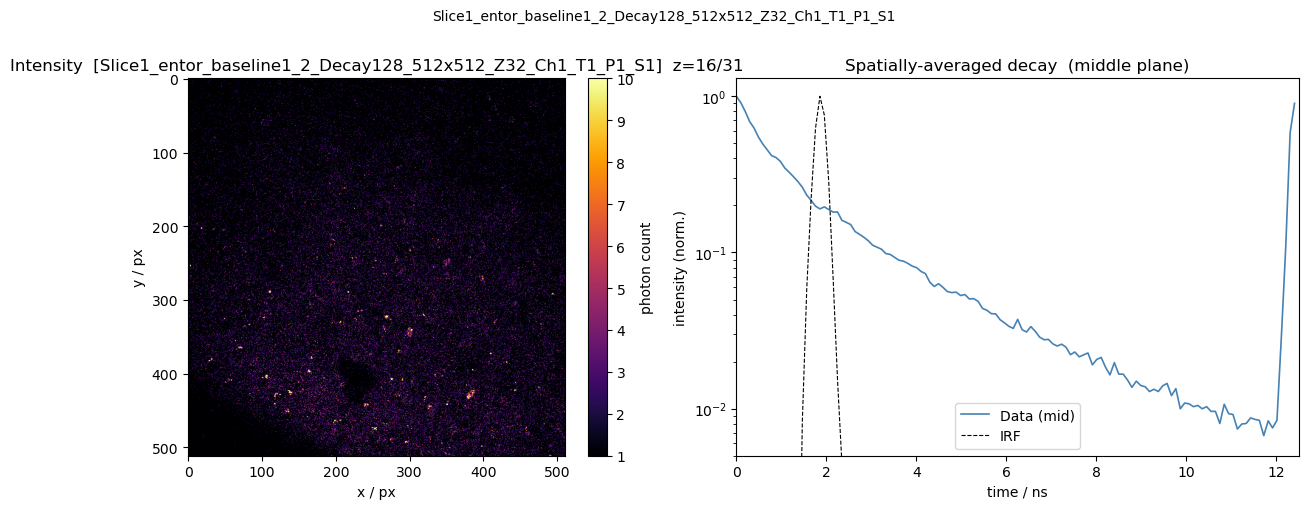

In [51]:
# ── analysis parameters (edit per experiment) ─────────────────────────────────
# Tcycle, xy_pixel_um, z_step_um: set in Step 0a (ISS .fbs.xml / Olympus .oir metadata, or the defaults)
threshold = 3
limits    = np.array([np.nan, np.nan])
szPhs     = 0.005
szBin     = 3

# ── lifetime per cell (Steps 14, 15, 17) ──────────────────────────────────────
fit_per_cell   = False         # True: multi-exponential Fit_decay per cell (Step 14) and per cell x timepoint (Step 17).
                               # False: per cell only model-free values (tav_pooled, phasor G/S, tau_phi, tau_mod);
                               # Fit_decay runs once on the pooled decay of all cells (Step 14) and of each timepoint (17).
                               # Slice3, 700 photons/cell: SD of a per-cell fit 0.34-0.68 ns, tav / tau_phi 0.08 ns.

# ── IRF (Step 5: one cell prepares it for every later step) ─────────────────
irf_tail_ns      = 2.5         # IRF kept within ±irf_tail_ns of its peak, 0 beyond: removes the echoes of the urea-SHG
                               # IRF recordings (~3.4 and ~4.9 ns after the peak; the slice decays have none). None = as measured
irf_width_mode   = 'auto'      # 'auto': rescale the IRF width to this recording when the IRF is not from the same session
                               # (no IRF .fbs.xml, or another date / laser period); 'always'; 'off' (IRF as measured)
irf_width_win_ns = 3.0         # fit window after the peak (ns): rising edge + early decay, before any reflection bump

# ── voxel dimensions (µm): xy_pixel_um / z_step_um set in Step 0a ─────────────

thresh_norm    = 0.55
nlm_h          = None
nlm_patch_size = 5
nlm_patch_dist = 6
nlm_fast       = True
rb_radius      = 30

Data_path_main = os.path.normpath(r"D:\Peredox_FLIM\XYZT1_336_X+0.50_Y+0.80_Decay128_512x512_Z186_Ch1_T1_P1_S1\XYZT1_336_X+0.50_Y+0.80_Decay128_512x512_Z186_Ch1_T1_P1_S1.tif")

# ── TIFF dimension order ───────────────────────────────────────────────────────
dim_data = 'TYX'
dim_irf  = 'TYX'

# ── file / folder pickers (uncomment for interactive selection) ───────────────
def _pick_file(title):
    root = tk.Tk(); root.withdraw(); root.attributes('-topmost', True)
    p = filedialog.askopenfilename(
        title=title, filetypes=[('TIFF files', '*.tif *.tiff'), ('All files', '*.*')])
    root.destroy()
    return p or None

def _pick_folder(title, initialdir=Data_path_main):
    # On Windows, askdirectory ignores initialdir for mapped network drives.
    # Temporarily chdir there so the dialog opens in the right place.
    _init = initialdir
    while _init and not os.path.isdir(_init):
        _parent = os.path.dirname(_init)
        if _parent == _init:
            _init = None; break
        _init = _parent
    _cwd = os.getcwd()
    if _init:
        os.chdir(_init)
    try:
        root = tk.Tk(); root.withdraw(); root.attributes('-topmost', True)
        p = filedialog.askdirectory(title=title, initialdir=_init)
        root.destroy()
    finally:
        os.chdir(_cwd)   # always restore kernel working directory
    return p or None

# ── paths — swap comments to switch between hardcoded and interactive ─────────
irf_path    = r"D:\Peredox_FLIM\Urea_SHG_IRF_FLIM_980nm_4_Decay128_512x512_Z1_Ch1_T1_P1_S1.tif"
# irf_path    = _pick_file('Select IRF TIFF')
data_folder = stitched_dir   # stitched TCSPC planes from Step 0d
# data_folder = _pick_folder('Select folder containing data TIFFs (z-stack)', initialdir=r'X:\FLIM_2026\test_data')

if not data_folder:
    raise RuntimeError('No data folder selected.')

# ── FName from the raw Vista file name ────────────────────────────────────────
FName = vista_info['base']

# ── analysis folder: reuse most recent or create new ─────────────────────────
force_new_analysis = False   # set True to always create a fresh dated folder

_name_tag = re.sub(r'_Decay\d+_.*$', '', FName)   # file name without the Vista suffix (_Decay128_512x512_...)
_existing = sorted(
    [d for d in glob.glob(os.path.join(data_folder, '*_FLIM_Analysis'))
     if os.path.isdir(d)],
    key=lambda d: (re.findall(r'(\d{8}_\d{4})_FLIM_Analysis$', d) or [''])[0]
)   # chronological by the YYYYMMDD_HHMM stamp (folders made before 2026-11-23 have no name in front)

if _existing and not force_new_analysis:
    newFolder = _existing[-1]   # most recent
    print(f'  Reusing existing analysis folder:{newFolder}')
    print('  → Cached files (.npz, .csv) in this folder will be loaded by later steps.')
    print('  → Set  force_new_analysis = True  to start a fresh dated folder.')
else:
    _ts       = datetime.now().strftime('%Y%m%d_%H%M')
    newFolder = os.path.join(data_folder, f'{_name_tag}_{_ts}_FLIM_Analysis')
    os.makedirs(newFolder, exist_ok=True)
    if force_new_analysis and _existing:
        print(f'  Created new analysis folder (force_new_analysis=True):{newFolder}')
    else:
        print(f'  Created analysis folder:{newFolder}')

print(f'  IRF:         {irf_path}')
print(f'  Data folder: {data_folder}')
print(f'  FName:       {FName}')

# ── natural sort ──────────────────────────────────────────────────────────────
def _natural_key(s):
    return [int(c) if c.isdigit() else c.lower() for c in re.split(r'(\d+)', s)]

# ── XML search helper ─────────────────────────────────────────────────────────
def _find_xml(tiff_path):
    base = re.sub(r'_Intensity.*$', '', os.path.splitext(os.path.basename(tiff_path))[0])
    for search_dir in [os.path.dirname(os.path.dirname(tiff_path)), os.path.dirname(tiff_path)]:
        hits = sorted(glob.glob(os.path.join(search_dir, '*.fbs.xml')))
        if hits:
            return max(hits, key=lambda p: len(os.path.commonprefix([base, os.path.basename(p)])))
    return None

# ── axis-reorder helper ───────────────────────────────────────────────────────
def _to_yxt(arr, order):
    order = list(order.upper())
    extra = [i for i, c in enumerate(order) if c not in ('T', 'Y', 'X')]
    if extra:
        arr   = arr.sum(axis=tuple(sorted(extra)))
        order = [c for c in order if c in ('T', 'Y', 'X')]
    y, x, t = order.index('Y'), order.index('X'), order.index('T')
    return np.transpose(arr, [y, x, t])

# ── enumerate z-planes ────────────────────────────────────────────────────────
data_paths = sorted(
    glob.glob(os.path.join(data_folder, '*.tif')) +
    glob.glob(os.path.join(data_folder, '*.tiff')),
    key=_natural_key)
n_planes = len(data_paths)
mid_idx  = n_planes // 2
print(f'\nFound {n_planes} planes in:  {data_folder}')
print(f'Middle plane  z={mid_idx}:  {os.path.basename(data_paths[mid_idx])}')

# ── load IRF metadata ─────────────────────────────────────────────────────────
meta_irf = None
xml_irf  = _find_xml(irf_path)
if xml_irf:
    meta_irf = read_fbs_metadata(xml_irf)
    print(f'\nIRF metadata:  {os.path.basename(xml_irf)}')
    print(f'  Tcycle={meta_irf["Tcycle"]:.4f} ns  nbin={meta_irf["nbin"]}  '
          f'gain={meta_irf["detector_gain"]}%  dwell={meta_irf["dwell_time_ms"]} ms/px')
else:
    print('\n  No .fbs.xml found for IRF')

# ── data metadata: the ISS .fbs.xml found in Step 0a (Tcycle is set there) ────
# Its ImageRegion is a Vista placeholder (±50 µm), so the voxel size stays the Step 0a one.
meta = fbs_meta
if meta:
    print(f'\nData metadata: {os.path.basename(fbs_xml)}')
    print(f'  Tcycle={Tcycle:.4f} ns  nbin={meta["nbin"]}  '
          f'gain={meta["detector_gain"]}%  dwell={meta["dwell_time_ms"]} ms/px  '
          f'excitation={meta["excitation_nm"]} nm')
else:
    print(f'\n  No .fbs.xml for the data — Tcycle = {Tcycle} ns (Step 0a default)')

print(f'Voxel size:  xy={xy_pixel_um} µm   z={z_step_um} µm   '
      f'anisotropy={z_step_um/xy_pixel_um:.2f}')

# ── Tcycle cross-check ────────────────────────────────────────────────────────
if meta_irf and meta:
    _dt = abs(meta_irf['Tcycle'] - meta['Tcycle'])
    if _dt > 0.01:
        warnings.warn(
            f'Tcycle mismatch: IRF={meta_irf["Tcycle"]:.4f} ns, '
            f'data={meta["Tcycle"]:.4f} ns (diff={_dt:.4f} ns). Using data Tcycle.',
            RuntimeWarning, stacklevel=2)
        print(f'WARNING: Tcycle mismatch — IRF={meta_irf["Tcycle"]:.4f}, data={meta["Tcycle"]:.4f} ns')
    else:
        print(f'\nTcycle cross-check OK  ({meta_irf["Tcycle"]:.4f} vs {meta["Tcycle"]:.4f} ns,  '
              f'diff={_dt:.5f} ns)')
elif meta_irf and not meta:
    print(f'IRF XML period {meta_irf["Tcycle"]:.4f} ns  (data: Step 0a default {Tcycle} ns, not overridden)')

_gain  = f"Gain {meta['detector_gain']}%"        if meta and meta['detector_gain']  is not None else ''
_dwell = f"Dwell {meta['dwell_time_ms']} ms/px"   if meta and meta['dwell_time_ms'] is not None else ''
meta_str = '  ·  '.join(s for s in [_gain, _dwell] if s)

# ── load IRF (1-D) ────────────────────────────────────────────────────────────
IRF_raw = tifffile.imread(irf_path).astype(float)
IRF = (_to_yxt(IRF_raw, dim_irf).sum(axis=(0, 1))
       if any(c in dim_irf.upper() for c in ('Y', 'X')) else IRF_raw.ravel())

# ── load middle plane as reference DataTCSPC ─────────────────────────────────
data_raw  = tifffile.imread(data_paths[mid_idx]).astype(float)
DataTCSPC = _to_yxt(data_raw, dim_data)
print(f'\nMiddle-plane DataTCSPC shape: {DataTCSPC.shape}  (ny, nx, nbin)')

# ── nbin check ────────────────────────────────────────────────────────────────
nbin_data = DataTCSPC.shape[2]
for _label, _m in [('data XML', meta), ('IRF XML', meta_irf)]:
    if _m and _m['nbin'] is not None and nbin_data != _m['nbin']:
        warnings.warn(
            f'nbin mismatch ({_label}): data has {nbin_data} bins, XML says {_m["nbin"]}.',
            RuntimeWarning, stacklevel=2)
print(f'nbin = {nbin_data}  ✓')

sumTCSPC = DataTCSPC.sum(axis=2)
maskPMT  = (sumTCSPC >= threshold).astype(float)
maskPMT[maskPMT == 0] = np.nan

_flat  = sumTCSPC.ravel(); _flat = _flat[_flat > 0]
lo_pct = np.percentile(_flat, 1)
hi_pct = np.percentile(_flat, 99.9)

_nbin_d  = DataTCSPC.shape[2]
_tau_d   = np.arange(_nbin_d) * (Tcycle / _nbin_d)
_decay   = DataTCSPC.sum(axis=(0, 1)).astype(float)
_irf_d   = IRF[:_nbin_d] / IRF[:_nbin_d].max()
_decay_n = _decay / _decay.max()

fig, axes = plt.subplots(1, 2, figsize=(13, 5))
im = axes[0].imshow(sumTCSPC, cmap='inferno', aspect='equal', origin='upper',
                    vmin=lo_pct, vmax=hi_pct)
axes[0].set_title(f'Intensity  [{FName}]  z={mid_idx}/{n_planes-1}', fontsize=12)
axes[0].set_xlabel('x / px'); axes[0].set_ylabel('y / px')
plt.colorbar(im, ax=axes[0], fraction=0.046, pad=0.04).set_label('photon count')
axes[1].semilogy(_tau_d, _decay_n, color='steelblue', linewidth=1.2, label='Data (mid)')
axes[1].semilogy(_tau_d, _irf_d,   color='k', linewidth=0.8, linestyle='--', label='IRF')
axes[1].set_xlabel('time / ns'); axes[1].set_ylabel('intensity (norm.)')
axes[1].set_title('Spatially-averaged decay  (middle plane)', fontsize=12)
axes[1].set_xlim(0, Tcycle); axes[1].set_ylim(5e-3, 1.3)
axes[1].legend()
_suptitle = FName + (f'  —  {meta_str}' if meta_str else '')
plt.suptitle(_suptitle, fontsize=10, y=1.01)
plt.tight_layout()
plt.show()

## Step 2: 3D pre-processing & Cellpose segmentation
- **Pre-processing** (NLM + rolling ball on the stitched segmentation intensity) → `vol_norm_3d`, `mask3d`
  (pixel masks of Steps 3–13). Reused when `*_sumTCSPC_3Dfilt_norm.tif` / `*_mask3d.tif` exist in `newFolder`.
- **Cellpose** (`multiday.segment_cellpose`, sizes in µm) → `cp_masks`. Masks are reused only if they were made
  with the same settings (`*_cellpose_masks.json`). Default input is the lightly smoothed raw intensity: the NLM
  output has a fibrous texture that Cellpose segments as cells. Tune the settings on a crop with the grid in
  `MultiDay_Reference.ipynb`.
- **Segmentation channel** `seg_source`: `'auto'` = the Olympus channel stitched in Step 0e when present (mCherry:
  no diffuse green background), else the time-projected FLIM intensity. The pre-processing (`vol_norm_3d`, `mask3d`)
  stays on the FLIM intensity: it defines the photon masks of Steps 3–13.
- **Fine-tuned model** `cp_model_path` (from `Cellpose_FineTune.ipynb`; None = generic `cpsam`): `cp_diameter_um` is then
  taken from the model (its training scale).
- **`use_subject_reference = True`** skips Cellpose: the cells come from the subject's curated reference (Step 2b).

> **To try here (2026-11-20):** the time-lapse notebook (`AnalyzeTCSPC_XYTZTime.ipynb`, Step 2) now segments a
> brightness-normalised photon sum (`vista_tiles.photon_sum_reference`, n_t = 1 works), builds the mask with 2D NLM +
> an ellipsoid rolling ball (`md.preprocess_volume(nlm='2d', bg='ellipsoid')`; the radius-30 px ball hollows small
> cells), runs Cellpose with `flow_threshold = 0` (0.4 dropped most somata in brain slices: 64 → 687 cells), drops
> low-contrast cells (`md.cell_quality`) and adds the cells to `mask3d`. Worth testing on tile data, especially for
> multi-day tracking: a more complete, consistent reference segmentation means more cells matched across sessions.

In [ ]:
# ── cell source ───────────────────────────────────────────────────────────────
use_subject_reference = False   # True: cells = the subject's curated reference labels (Step 2b); Cellpose skipped

# ── Cellpose parameters (sizes in µm; pre-processing parameters are set in Step 1) ──
seg_source          = 'auto'       # 'auto' = Olympus channel (Step 0e) if present, else 'flim'; or 'olympus' / 'flim'
cp_input            = 'smoothed'   # 'smoothed' raw intensity, or 'nlm' (FLIM NLM + rolling ball, the pre-2026-11 input)
cp_mode             = '2d_stitch'  # '2d_stitch' (per plane, linked across z) or '3d' (very slow at small diameters)
cp_diameter_um      = 8.0          # expected object diameter in xy
cp_cellprob_thresh  = -1.5         # lower -> more / larger objects (Cellpose default 0)
cp_flow_threshold   = 0.4          # 2D only (Cellpose ignores it in 3D); raise to accept more objects
cp_stitch_threshold = 0.25         # 2D: IoU needed to link masks of neighbouring planes
cp_min_volume_um3   = None         # None = sphere of half the diameter
cp_model_path       = None         # fine-tuned model (Cellpose_FineTune.ipynb); None = generic cpsam
cp_gpu              = True
_rerun_cp           = False        # True: re-run Cellpose even if masks with these settings exist
# previous settings, for reference: cp_input='nlm', cp_mode='3d', cp_diameter_um=49.5, cp_cellprob_thresh=0.9,
# cp_min_volume_um3=1470 (=500 voxels) -> masks ~42 µm tall that follow the NLM texture

_voxel_sp    = (z_step_um, xy_pixel_um, xy_pixel_um)
if cp_model_path:   # the model was trained at one scale: use its diameter
    _ft_meta = json.load(open(cp_model_path + '.json'))
    if _ft_meta['diameter_um'] != cp_diameter_um:
        print(f'cp_diameter_um {cp_diameter_um} -> {_ft_meta["diameter_um"]} µm (training scale of '
              f'{os.path.basename(cp_model_path)})')
        cp_diameter_um = _ft_meta['diameter_um']
if seg_source == 'auto':
    seg_source = 'olympus' if stitch_oir else 'flim'
if seg_source == 'olympus' and not stitch_oir:
    raise RuntimeError("seg_source='olympus' but Step 0e produced no Olympus channel")
if seg_source == 'olympus' and cp_input == 'nlm':
    raise ValueError("cp_input='nlm' is the FLIM pre-processing; use cp_input='smoothed' with seg_source='olympus'")
_seg_name    = f'Olympus {oir_ch["name"]} ({oir_ch["filter"]})' if seg_source == 'olympus' else 'FLIM intensity'
_cp_settings = dict(source=seg_source, channel=oir_ch['id'] if seg_source == 'olympus' else None,
                    spacing=list(_voxel_sp), input=cp_input, mode=cp_mode, diameter_um=cp_diameter_um,
                    cellprob_threshold=cp_cellprob_thresh, flow_threshold=cp_flow_threshold,
                    stitch_threshold=cp_stitch_threshold, min_volume_um3=cp_min_volume_um3,
                    model=[cp_model_path, os.path.getmtime(cp_model_path)] if cp_model_path else None)

_filt_path = os.path.join(newFolder, f'{FName}_sumTCSPC_3Dfilt_norm.tif')
_mask_path = os.path.join(newFolder, f'{FName}_mask3d.tif')
_cp_path   = os.path.join(newFolder, f'{FName}_cellpose_masks.tif')
_cp_json   = _cp_path.replace('.tif', '.json')        # settings the masks were made with

# ── 3D intensity: per-tile normalised, feather-blended (Step 0d) ──────────────
# (summing data_paths would double-count photons in the tile overlaps)
vol_sum3d = tifffile.imread(stitch['int_path']).astype(np.float32)
vol_seg3d = tifffile.imread(stitch_oir).astype(np.float32) if seg_source == 'olympus' else vol_sum3d
if vol_seg3d.shape != vol_sum3d.shape:
    raise ValueError(f'{_seg_name} volume {vol_seg3d.shape} != FLIM intensity {vol_sum3d.shape}')
print(f'Segmentation input: {_seg_name}')

# ── pre-processing: NLM + rolling ball -> vol_norm_3d, mask3d ─────────────────
_newer = lambda p, *srcs: os.path.exists(p) and all(os.path.getmtime(p) > os.path.getmtime(s) for s in srcs)
if _newer(_filt_path, stitch['int_path']) and _newer(_mask_path, stitch['int_path']):
    vol_norm_3d = tifffile.imread(_filt_path).astype(np.float32)
    mask3d      = tifffile.imread(_mask_path).astype(bool)
    print(f'Reloaded  vol_norm_3d / mask3d  {vol_norm_3d.shape}  <- {os.path.basename(_filt_path)}')
else:
    print(f'Loaded stitched intensity {vol_sum3d.shape}  <- {os.path.basename(stitch["int_path"])}')
    vol_norm_3d = md.preprocess_volume(vol_sum3d, nlm_h=nlm_h, patch_size=nlm_patch_size,
                                       patch_distance=nlm_patch_dist, fast_mode=nlm_fast, rb_radius=rb_radius)
    mask3d = vol_norm_3d >= thresh_norm
    tifffile.imwrite(_filt_path, vol_norm_3d)
    tifffile.imwrite(_mask_path, mask3d.astype(np.uint8))
    print(f'Saved: {_filt_path}')
print(f'Valid voxels: {mask3d.sum():,} / {mask3d.size:,}  ({100*mask3d.mean():.1f}%)  thresh_norm={thresh_norm}')

# ── Cellpose (skipped when the cells come from the subject reference) ────────
cp_masks, n_cells = None, 0
cell_tag   = ''          # file-name tag of the Steps 14-16 outputs (Step 2b sets it for reference cells)
cells_path = _cp_path    # label file the Steps 14-16 caches must be newer than
if use_subject_reference:
    print('Cellpose skipped: cells come from the subject reference (Step 2b).')
else:
    _old = json.load(open(_cp_json)) if os.path.exists(_cp_json) else None
    _seg_src = stitch_oir if seg_source == 'olympus' else stitch['int_path']
    if _newer(_cp_path, _seg_src) and _old == _cp_settings and not _rerun_cp:
        cp_masks = tifffile.imread(_cp_path)
        print(f'Reloaded  cp_masks  {cp_masks.shape}  <- {os.path.basename(_cp_path)}')
    else:
        if os.path.exists(_cp_path) and _old is None:   # masks from before the settings file: keep them
            os.replace(_cp_path, _cp_path.replace('.tif', '_old.tif'))
            print(f'Kept previous masks as {os.path.basename(_cp_path).replace(".tif", "_old.tif")}')
        _cp_in = vol_norm_3d if cp_input == 'nlm' else md.seg_input(vol_seg3d, _voxel_sp)
        print(f'Running Cellpose ({cp_mode}, {os.path.basename(cp_model_path) if cp_model_path else "cpsam"}) on '
              f'{_seg_name}  d={cp_diameter_um} µm  cellprob={cp_cellprob_thresh}  input={cp_input}  gpu={cp_gpu}...',
              flush=True)
        _t0 = datetime.now()
        cp_masks = md.segment_cellpose(_cp_in, _voxel_sp, cp_diameter_um, mode=cp_mode,
                                       cellprob_threshold=cp_cellprob_thresh, flow_threshold=cp_flow_threshold,
                                       stitch_threshold=cp_stitch_threshold, min_volume_um3=cp_min_volume_um3,
                                       gpu=cp_gpu, model_path=cp_model_path)
        tifffile.imwrite(_cp_path, cp_masks)
        with open(_cp_json, 'w') as _f:
            json.dump(_cp_settings, _f, indent=1)
        print(f'Done in {(datetime.now() - _t0).total_seconds():.0f} s.  Saved: {_cp_path}')
    n_cells = int(cp_masks.max())
    _st = md.mask_stats(cp_masks, _voxel_sp)
    print(f'{_st["n"]} cells  |  median xy diameter {_st["diam_xy_um"]:.1f} µm  |  '
          f'median z extent {_st["z_extent_um"]:.1f} µm')

# ── QC: middle plane ──────────────────────────────────────────────────────────
from skimage.segmentation import find_boundaries
def _mid01(v):   # middle plane, lightly smoothed, scaled to [0, 1]
    m = md.seg_input(v[mid_idx:mid_idx + 1], _voxel_sp, sigma_um=(0, 0.7, 0.7))[0]
    return np.clip(m / np.percentile(m, 99.7), 0, 1)
_flim_mid = _mid01(vol_sum3d)
_seg_mid  = _mid01(vol_seg3d) if seg_source == 'olympus' else _flim_mid
_panels   = [(_flim_mid, f'FLIM intensity (σ 0.7 µm)  z={mid_idx}')]
if seg_source == 'olympus':
    _panels.append((_seg_mid, f'{_seg_name} (σ 0.7 µm)  z={mid_idx}'))
_panels  += [(vol_norm_3d[mid_idx], f'NLM + rolling ball  z={mid_idx}'),
             (mask3d[mid_idx].astype(float), f'mask  (thresh_norm={thresh_norm})')]
if cp_masks is not None:
    _bnd = find_boundaries(cp_masks[mid_idx], mode='inner')
    for _im, _nm in [(_seg_mid, _seg_name)] + ([(_flim_mid, 'FLIM intensity')] if seg_source == 'olympus' else []):
        _rgb = np.dstack([_im] * 3)
        _rgb[_bnd] = (1.0, 0.25, 0.1)
        _panels.append((_rgb, f'Cellpose outlines on {_nm}  ({n_cells} cells)'))
_ncol = min(3, len(_panels))
_nrow = -(-len(_panels) // _ncol)
_fig_pre, _axes_pre = plt.subplots(_nrow, _ncol, squeeze=False,
                                   figsize=(6 * _ncol, 6 * _nrow * vol_sum3d.shape[1] / vol_sum3d.shape[2]))
for _a in _axes_pre.ravel():
    _a.axis('off')
for _a, (_img, _ttl) in zip(_axes_pre.ravel(), _panels):
    _a.imshow(_img, cmap='gray' if _img.ndim == 2 else None, interpolation='nearest')
    _a.set_title(_ttl, fontsize=10)
plt.suptitle(f'{FName}  —  Step 2: pre-processing & segmentation  (z={mid_idx}/{n_planes-1})', fontsize=9)
plt.tight_layout(rect=(0, 0, 1, 0.98))
plt.show()

Segmentation input: FLIM intensity
Loaded stitched intensity (32, 512, 512)  <- Slice1_entor_baseline1_2_Decay128_512x512_Z32_Ch1_T1_P1_S1_stitched_intensity.tif
Noise sigma ~ 0.16801   h = 0.13440
Running 3D NLM (CPU)... 

## Step 2b: cells from the subject reference (multi-day tracking)
Runs only with `use_subject_reference = True` (Step 2). Needs the subject's curated `reference_labels.tif`
(`MultiDay_Reference.ipynb`).
1. **Register** this session's segmentation volume (Olympus red when present, else the FLIM intensity; fixed) to the
   reference (moving), in µm: MIP phase correlation
   + rotation sweep + depth search, then SimpleITK rigid (optionally a bounded B-spline) → `registration/*.h5`.
2. **Transfer labels**: reference labels → this session's grid (nearest neighbour; the TCSPC data are never
   resampled), then a per-cell local shift search (±3 µm) → `registration/<FName>_ref<id>_labels.tif`.
3. **QC per cell** (`<FName>_ref<id>_cell_qc.csv`): `ok`, `partial` (cut by the FOV or coverage), `low_match`
   (local NCC < 0.3), `outside`. Cells are flagged, not dropped; `cell_id` = the global reference ID.
4. The session is added to `<subject>/sessions.json`; Steps 14–16 then write `<FName>_ref<id>_*.csv`.

In [ ]:
# ── Step 2b: subject reference -> session labels ──────────────────────────────
subject_id        = vista_info['base'].split('_')[1]   # 'XYZT1_336_...' -> '336'
subject_root      = r'D:\Peredox_FLIM\subjects'
reg_stages        = ('rigid',)          # add 'bspline' if the overlay shows residual local warping
refine_shift_um   = (3.0, 3.0, 3.0)     # per-cell local search (z, y, x) after the label transfer
rerun_subject_reg = False               # True: redo registration + label transfer

if not use_subject_reference:
    print('Step 2b skipped (use_subject_reference = False): cells from Cellpose (Step 2).')
else:
    importlib.reload(md)
    subject_dir = os.path.join(subject_root, subject_id)
    _ref = md.load_reference(subject_dir)
    if _ref['labels'] is None:
        raise RuntimeError(f'No curated reference_labels.tif in {subject_dir} — run MultiDay_Reference.ipynb first.')
    cell_tag   = f'_ref{subject_id}'
    _reg_dir   = os.path.join(newFolder, 'registration')
    os.makedirs(_reg_dir, exist_ok=True)
    _tf_path   = os.path.join(_reg_dir, f'{FName}_to_ref{subject_id}.h5')
    cells_path = os.path.join(_reg_dir, f'{FName}{cell_tag}_labels.tif')
    _qc_path   = os.path.join(newFolder, f'{FName}{cell_tag}_cell_qc.csv')
    _ses_sp    = (z_step_um, xy_pixel_um, xy_pixel_um)
    _ses_cov   = tifffile.imread(stitch['cov_path'])
    _ses_p     = md.reg_prep(vol_seg3d, _ses_sp)      # Olympus red when present (Step 2), else the FLIM intensity
    _ref_p     = md.reg_prep(_ref['vol'], _ref['spacing'])

    # ── registration: session (fixed) -> reference (moving) ───────────────────
    if os.path.exists(_tf_path) and not rerun_subject_reg:
        T_ref, reg_summary = md.load_transform(_tf_path)
        print(f'Reloaded transform <- {os.path.basename(_tf_path)}')
    else:
        _reg = md.register_session(_ref_p, _ref['spacing'], _ses_p, _ses_sp, mov_mask=_ses_cov > 0,
                                   stages=reg_stages)
        md.save_transform(_tf_path, _reg, session=FName, reference=_ref['meta']['source'])
        T_ref, reg_summary = md.load_transform(_tf_path)
        print(f'Saved transform -> {_tf_path}')
    print(f'NCC per stage: { {k: round(v, 3) for k, v in reg_summary["ncc"].items()} }')

    # ── label transfer + per-cell refinement + QC ─────────────────────────────
    _ref_w = md.warp_to_session(_ref_p, _ref['spacing'], T_ref, vol_sum3d.shape, _ses_sp)
    _newer = lambda p, *srcs: os.path.exists(p) and all(os.path.getmtime(p) > os.path.getmtime(s) for s in srcs)
    if (not rerun_subject_reg and _newer(cells_path, _tf_path, md.subject_paths(subject_dir)['ref_labels'])
            and os.path.exists(_qc_path)):
        cp_masks   = tifffile.imread(cells_path)
        df_cell_qc = pd.read_csv(_qc_path)
        print(f'Reloaded session labels <- {os.path.basename(cells_path)}')
    else:
        _lab0 = md.warp_to_session(_ref['labels'], _ref['spacing'], T_ref, vol_sum3d.shape, _ses_sp, labels=True)
        cp_masks, _df_ref = md.refine_cells(_lab0, _ses_p, _ref_w, _ses_sp, max_shift_um=refine_shift_um)
        df_cell_qc = md.cell_qc(_ref['labels'], _ref['spacing'], cp_masks, _ses_sp, coverage=_ses_cov,
                                refine_df=_df_ref)
        tifffile.imwrite(cells_path, cp_masks.astype(np.uint16), compression='zlib')
        df_cell_qc.to_csv(_qc_path, index=False)
        print(f'Saved session labels -> {cells_path}')
    n_cells = int(_ref['labels'].max())     # global IDs: rows 1 .. max reference ID
    md.update_sessions(subject_dir, session=FName, date=((fbs_meta or {}).get('datetime') or '')[:10] or md.session_date(raw_path), raw_path=raw_path,
                       analysis_dir=newFolder, cell_tag=cell_tag, transform=_tf_path, labels=cells_path,
                       qc=_qc_path)
    print(f'Reference cells: {len(df_cell_qc)}  |  flags: {df_cell_qc.flag.value_counts().to_dict()}')

    md.plot_registration_qc(_ses_p, _ref_w, _ses_sp, mask=_ses_cov > 0, labels=cp_masks, z=mid_idx,
                            title=f'{FName}  ->  reference {subject_id}')
    plt.show()

## Step 3: Mask preparation (middle plane)
Extracts the middle-plane slice of `vol_norm_3d` and thresholds at `thresh_norm` to produce `maskTCSPC` (float, 0/1) and `maskFilt_bool` (boolean).

In [33]:
# ── masks from 3D pre-processed volume (middle plane) ────────────────────────
maskTCSPC     = mask3d[mid_idx].astype(float)
maskFilt_bool = mask3d[mid_idx]

# ── save middle-plane intensity maps ─────────────────────────────────────────
imwrite(os.path.join(newFolder, f'{FName}_sumTCSPC.tif'), sumTCSPC.astype(np.float32))
imwrite(os.path.join(newFolder, f'{FName}_sumTCSPC_filt_norm.tif'),
        vol_norm_3d[mid_idx].astype(np.float32))

print(f'maskTCSPC valid pixels: {maskFilt_bool.sum():.0f}  (thresh_norm={thresh_norm})')

maskTCSPC valid pixels: 90820  (thresh_norm=0.55)


## Step 5: IRF and peak realignment
One cell prepares the data alignment and the IRF for every later step (Step 4, *IRF preprocessing*, merged in on
2026-11-24). It starts from what Step 1 loaded (`data_raw`, `IRF`), so re-running it gives the same result until Step 1
loads other files.

- **Data**: circular shift so the fluorescence peak of the middle plane lands at 8 % of `nbin` (`target`) →
  `shift_data`, applied by every step that reads planes from disk (11, 13, 14, 17).
- **IRF** → `IRF2` (`flim_helpers.prepare_irf`):
  1. `clean_irf`: peak → `target`, baseline 0, and 0 further than `irf_tail_ns` (2.5 ns, Step 1) from the peak. The
     urea-SHG IRFs have echoes ~3.4 and ~4.9 ns after the peak that the slice decays do not have. Until 2026-11-24 the
     tav maps (Step 8), the phasor reference (Steps 11, 15) and Step 13 kept them, while Step 14 cut them when it found
     no bump and the width rescale cut them when applied: the IRF mean arrival time then differed by 0.03–0.045 ns
     between those paths (Slice3: `tau_phi` ~0.02 ns, `tau_mod` ~0.05 ns). Every step now uses the same IRF.
  2. Width (`irf_width_mode`, below).
- `IRF2` is used unchanged by every later step: tav reference `H` (Steps 8, 13, 14, 17), phasor reference (Steps 11,
  14, 15, 17) and all fits (Steps 14, 17). Its fingerprint `irf_key` is stored with the Step 14 caches, which are
  recomputed when the IRF changes.
- Output: printout, QC plots (IRF width: rising edge and residuals; alignment: IRF as loaded, `IRF2` and data) and
  `*_irf.json` (IRF file, `irf_key`, settings, width factor and chi2).

**IRF width (since 2026-11-23; `irf_width_mode` in Step 1).** An IRF recorded in another session can be wider or narrower
than the instrument response of the recording. On the 2026-11-10 brain slices, with the urea-SHG IRFs of 2 and 6 Nov:
- the data rose faster than any decay convolved with the measured IRF (impossible for a convolution), and `Fit_decay`
  compensated with a ~0.025 ns component holding ~9 % of the photons;
- a fitted width factor of 0.54–0.60 (2 Nov IRF) / 0.58–0.66 (6 Nov IRF) on Slice3 baseline, Slice3 sucrose and Slice1,
  the same with a 3 ns or the full window, brought the pooled fit's chi2 from 286 to 34 and the fast component from
  9 % to 0 %, and gave the same mean lifetime (1.91 ns) with either IRF;
- not the IRF's laser period (all November data and IRFs at 80 MHz; a ~53 MHz IRF would need broadening, not
  narrowing) and hardly count rate (2.7 → 3.4 bins from the dimmest to the brightest IRF pixels).

`fit_irf_width` (flim_helpers) fits, on the middle plane's decay up to `irf_width_win_ns` (3 ns) after the peak, the IRF
(echoes cut) stretched by a factor *s* about its peak and shifted by *c* bins, convolved with 2 free exponentials +
background (nuisance parameters); *s* = 1 gives the chi2 of the measured width. When chi2 drops by more than 20 %, the
rescaled IRF (*s* applied, *c* not: IRF and data stay peak-aligned and `Fit_decay` fits its own shift) becomes `IRF2`.
`'auto'` fits when the IRF has no `.fbs.xml` or its date or laser period differs from the data's, `'always'` fits
anyway, `'off'` keeps the measured width. The fit takes < 1 s. An older z-stack (XYZ_288, its own IRF): chi2 94 → 90,
not applied. An IRF recorded in the same session, with its `.fbs.xml`, is still the better reference.


nbin = 128,  dt = 0.0977 ns
Target peak frame: 10 / 128  (7.8%)
Data  peak was frame  19,  shifted by -9
IRF   peak was frame  19,  shifted by -9


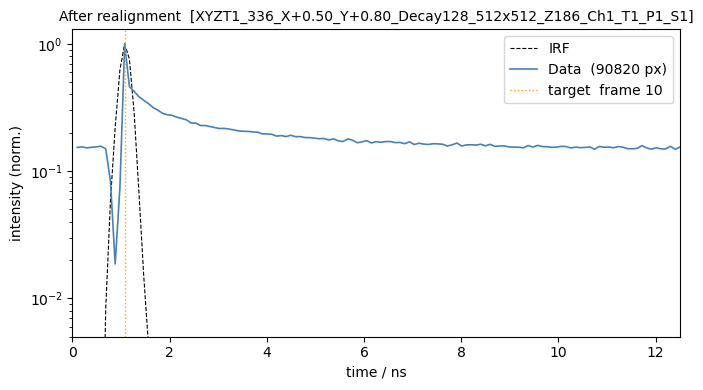

In [35]:
## Step 5: IRF and peak realignment: the one cell that prepares the data alignment and the IRF of every later step
# Starts from what Step 1 loaded (data_raw, IRF): re-running it gives the same result until Step 1 loads other files.
#   data: circular shift so the fluorescence peak of the middle plane lands at 8 % of nbin (target) -> shift_data,
#         applied by every step that reads planes from disk (11, 13, 14, 17)
#   IRF:  flim_helpers.prepare_irf (see the Step 5 notes)
#         1. peak -> target, baseline 0, 0 beyond irf_tail_ns from the peak (echoes of the IRF recording)  [clean_irf]
#         2. width rescaled to this recording when the IRF is not from the same session (irf_width_mode)  [fit_irf_width]
#         -> IRF2, used unchanged by every later step: tav reference H (Steps 8, 13, 14, 17), phasor reference
#            (Steps 11, 14, 15, 17), all fits (Steps 14, 17). irf_key, its fingerprint, is stored with the Step 14
#            caches, which are recomputed when the IRF changes.
import json as _json
import flim_helpers as _fh_mod; importlib.reload(_fh_mod)
from flim_helpers import prepare_irf, irf_session, plot_irf_width

# ── data and IRF as loaded (Step 1); bin count check ─────────────────────────
DataTCSPC = _to_yxt(data_raw, dim_data)              # middle plane
_irf_in   = np.asarray(IRF, dtype=float).ravel()     # IRF summed to 1-D
Ix        = _irf_in.size
nbin      = DataTCSPC.shape[2]
if nbin != Ix:
    raise ValueError(f'Bin count mismatch: data {nbin} bins, IRF {Ix} bins. Check dim_data / dim_irf (Step 1); the '
                     'retired bin-alignment cell at the end of the notebook handles a true mismatch.')
dt     = Tcycle / nbin
tau    = np.arange(1, nbin + 1) * dt
target = int(round(0.08 * nbin))
print(f'nbin = {nbin},  dt = {dt:.4f} ns,  target peak bin {target} / {nbin} ({100 * target / nbin:.1f}%)')

# ── data: fluorescence peak (middle plane, pixel mask) → target ──────────────
maskPixel    = mask3d[mid_idx]
decay_masked = DataTCSPC[maskPixel].sum(axis=0).astype(float)
peak_data    = int(np.argmax(decay_masked))
shift_data   = target - peak_data
DataTCSPC    = np.roll(DataTCSPC, shift_data, axis=2)
print(f'Data peak was bin {peak_data:3d},  shifted by {shift_data:+d}')

# ── IRF: peak → target, echoes cut, width (irf_tail_ns, irf_width_mode, irf_width_win_ns: Step 1) ──
_same_session, _why = irf_session(meta_irf, meta)
_y_w = DataTCSPC.sum(axis=(0, 1)).astype(float)      # whole middle plane: the decay the IRF width is fitted to
_irf = prepare_irf(_irf_in, _y_w, dt, target, tail_ns=irf_tail_ns, width_mode=irf_width_mode,
                   same_session=_same_session, win_ns=irf_width_win_ns)
IRF2, irf_key, irf_width = _irf['irf'], _irf['key'], _irf['width']
print(f'IRF  peak was bin {int(np.argmax(_irf_in)):3d},  moved to {target}'
      + (f';  baseline 0 beyond ±{irf_tail_ns} ns of the peak (echoes cut)' if irf_tail_ns is not None
         else ';  tail as measured (irf_tail_ns = None)'))
if irf_width is None:
    print(f'IRF width fit skipped ({_why}; irf_width_mode = {irf_width_mode!r}).')
else:
    print(f'IRF width fit ({_why}): factor {irf_width["s"]:.3f} (shift {irf_width["c"]:+.2f} bins, not applied);  '
          f'chi2 {irf_width["chi2_measured"]:.1f} with the measured width → {irf_width["chi2_fitted"]:.1f}'
          + ('  → IRF2 rescaled' if irf_width['apply'] else '  → < 20 % better: width kept as measured'))
    plot_irf_width(irf_width, tau, _y_w, target, irf_width_win_ns, title=f'[{FName}]')
with open(os.path.join(newFolder, f'{FName}_irf.json'), 'w') as _f:    # record of the IRF used by Steps 6-17
    _json.dump(dict(irf=os.path.basename(irf_path), irf_key=irf_key, tail_ns=irf_tail_ns, reason=_why,
                    width_mode=irf_width_mode, win_ns=irf_width_win_ns,
                    **({} if irf_width is None else
                       dict(factor=irf_width['s'], shift_bins=irf_width['c'], chi2_measured=irf_width['chi2_measured'],
                            chi2_fitted=irf_width['chi2_fitted'], applied=irf_width['apply']))), _f, indent=1)
print(f'IRF2 (Steps 6-17): key {irf_key},  mean arrival time {np.dot(tau, IRF2) / IRF2.sum():.4f} ns  '
      f'→ {FName}_irf.json')

# ── sanity-check plot ─────────────────────────────────────────────────────────
_decay_aligned = DataTCSPC[maskPixel].sum(axis=0).astype(float)
_irf_loaded    = np.roll(_irf_in, target - int(np.argmax(_irf_in)))

fig_align, ax_align = plt.subplots(figsize=(7, 4))
ax_align.semilogy(tau, _irf_loaded / _irf_loaded.max(), color='0.7', linewidth=0.8, label='IRF as loaded')
ax_align.semilogy(tau, IRF2 / IRF2.max(), '--k', linewidth=0.8, label='IRF2 (used by Steps 6-17)')
ax_align.semilogy(tau, _decay_aligned / _decay_aligned.max(), color='steelblue', linewidth=1.2,
                  label=f'Data  ({maskPixel.sum()} px)')
ax_align.axvline(tau[target], color='orange', linewidth=1, linestyle=':', label=f'target  bin {target}')
ax_align.set_xlabel('time / ns')
ax_align.set_ylabel('intensity (norm.)')
ax_align.set_title(f'After realignment  [{FName}]' + (f'\n{meta_str}' if meta_str else ''), fontsize=10)
ax_align.set_xlim(0, Tcycle)
ax_align.set_ylim(5e-3, 1.3)
ax_align.legend()
fig_align.tight_layout()
plt.show()


## Step 6: Masked decay & time axis
Builds the time axis `tau` and computes the spatially-masked average decay `tmp1` used for alignment and fitting.

In [11]:
# DataTCSPC = np.roll(DataTCSPC, 2, axis=2)   # 2-bin shift -- not needed for new instrument

dt  = Tcycle / nbin
tau = np.arange(1, nbin + 1) * dt               # time axis (ns)

# masked average decay (pixels >= threshold) -- consistent with maskPixel
# convert maskTCSPC to boolean for indexing, but keep original maskPixel for stats
maskTCSPCbool = maskTCSPC.astype(bool)
tmp1 = DataTCSPC[maskPixel].sum(axis=0).astype(float)

tmp = tmp1 / tmp1.max()
irf = IRF2 / IRF2.max()

print(f'dt = {dt:.4f} ns,  tau: {tau[0]:.3f} to {tau[-1]:.3f} ns')
print(f'Total photons in masked area: {tmp1.sum():.0f}  ({maskPixel.sum()} pixels)')


dt = 0.0974 ns,  tau: 0.097 to 12.462 ns
Total photons in masked area: 281379  (54782 pixels)


## Step 7: Apply count-threshold mask
Zeroes out pixels below `threshold` photon counts before the lifetime computation.

In [12]:
bc = (slice(None), slice(None)) + (np.newaxis,) * (DataTCSPC.ndim - 2)
DataTCSPC = DataTCSPC * maskTCSPC[bc]
print(f'Pixels zeroed out: {(maskTCSPC == 0).sum():.0f}')

Pixels zeroed out: 1354596


## Step 8: Mean-arrival-time lifetime (tav)
**Key equations:**
- `H = sum(tau * IRF) / sum(IRF)` — mean arrival time of the IRF (instrument offset)
- `F[x,y] = sum(tau * data[x,y]) / sum(data[x,y])` — mean photon arrival time per pixel
- `tav = F - H` — fluorescence lifetime estimate per pixel (ns)

C:\Users\Andrea\AppData\Local\Temp\ipykernel_64296\715636258.py:10: RuntimeWarning: invalid value encountered in divide
  F = (T * DataTCSPC).sum(axis=2) / DataTCSPC.sum(axis=2)


H (IRF mean arrival time): 1.3568 ns
tav stats (masked) -- min: 0.006 ns,  mean: 3.140 ns,  max: 7.600 ns


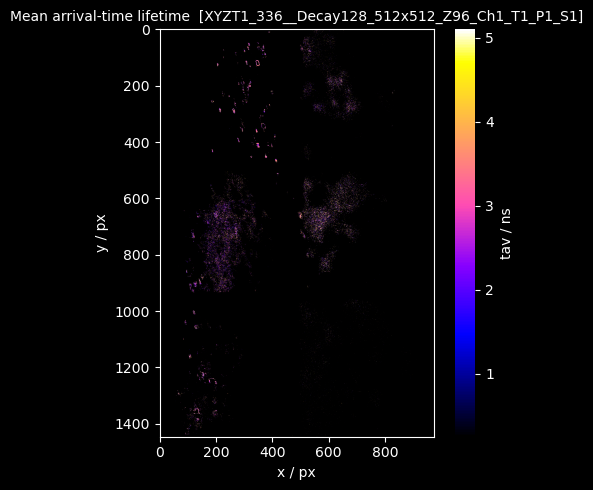

In [13]:
DataTCSPC = DataTCSPC.astype(float)
if DataTCSPC.ndim == 3:
    DataTCSPC = DataTCSPC[:, :, :, np.newaxis]

nx, ny, nbin, nch = DataTCSPC.shape
T = tau[np.newaxis, np.newaxis, :, np.newaxis]

H = float(np.dot(tau, IRF2) / IRF2.sum())

F = (T * DataTCSPC).sum(axis=2) / DataTCSPC.sum(axis=2)
F = np.nan_to_num(F)

tag = DataTCSPC.sum(axis=2).squeeze()
tav = (F - H).squeeze()
tav = np.clip(tav, 0, None)

print(f'H (IRF mean arrival time): {H:.4f} ns')
valid_tav = tav[maskTCSPCbool & (tav > 0)]
if valid_tav.size > 0:
    print(f'tav stats (masked) -- min: {valid_tav.min():.3f} ns,  '
          f'mean: {valid_tav.mean():.3f} ns,  max: {valid_tav.max():.3f} ns')

_tav_disp = tav.copy().astype(float)
_tav_disp[~maskTCSPCbool] = np.nan
_pos = _tav_disp[np.isfinite(_tav_disp) & (_tav_disp > 0)]
_vmin = float(np.percentile(_pos,  1)) if _pos.size else 0.0
_vmax = float(np.percentile(_pos, 90)) if _pos.size else 1.0

fig, ax = plt.subplots(figsize=(6, 5), facecolor='black')
ax.set_facecolor('black')
im = ax.imshow(_tav_disp, cmap='gnuplot2', aspect='equal', origin='upper',
               vmin=_vmin, vmax=_vmax)
cbar = plt.colorbar(im, ax=ax, fraction=0.046, pad=0.04)
cbar.set_label('tav / ns', color='white')
cbar.ax.yaxis.set_tick_params(color='white')
plt.setp(cbar.ax.yaxis.get_ticklabels(), color='white')
cbar.outline.set_visible(False)
ax.set_title(f'Mean arrival-time lifetime  [{FName}]' + (f'\n{meta_str}' if meta_str else ''),
             fontsize=10, color='white')
ax.set_xlabel('x / px', color='white')
ax.set_ylabel('y / px', color='white')
ax.tick_params(colors='white')
for spine in ax.spines.values():
    spine.set_edgecolor('white')
plt.tight_layout()
plt.show()

## Step 9: Bilateral filter on tav
Edge-preserving smooth of the lifetime map. `sigma_spatial` controls neighbourhood size; `sigma_lifetime` (ns) controls how much lifetime difference is tolerated — sharp compartment boundaries are preserved while shot-noise within a compartment is averaged. Overwrites `tav` in place; skip to keep the raw map.

tav std (masked, positive pixels): 1.453 ns
Using σ_lifetime = 0.726 ns for bilateral filter


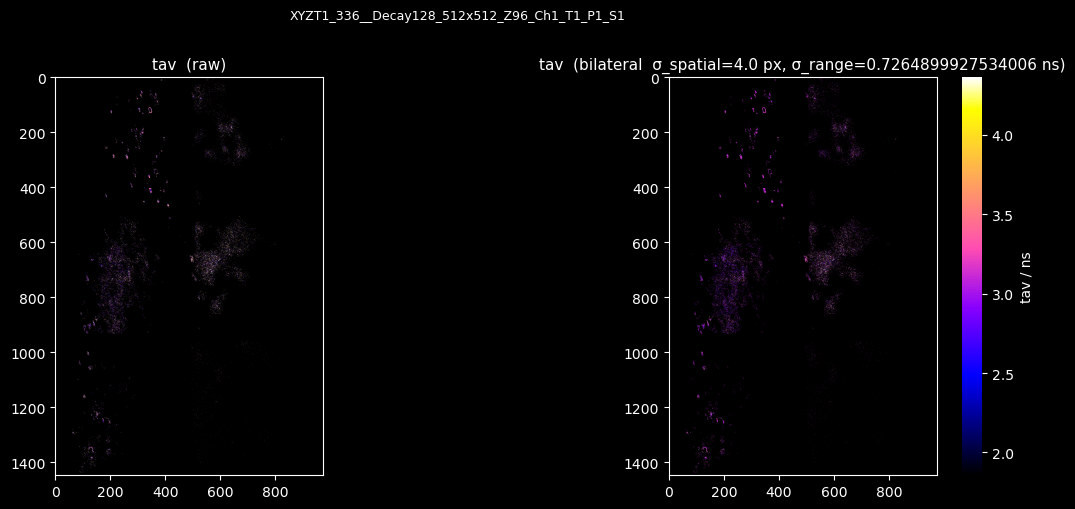

tav updated  (bilateral filtered).  Mean: 3.140 ns,  std: 0.936 ns


In [14]:
# ── parameters ────────────────────────────────────────────────────────────────
sigma_spatial   = 4.0   # spatial Gaussian σ (pixels)   — larger = more smoothing
sigma_lifetime  = 0.4   # range σ (ns) — lifetimes within this are averaged;
                        #   increase to smooth across compartments, decrease to sharpen edges

# calc std of tav for later use in range-based filtering (optional)
tav_std = np.nanstd(tav[maskTCSPCbool & (tav > 0)])
print(f'tav std (masked, positive pixels): {tav_std:.3f} ns')
sigma_lifetime = max(sigma_lifetime, 0.5 * tav_std)
print(f'Using σ_lifetime = {sigma_lifetime:.3f} ns for bilateral filter')

# ── apply ─────────────────────────────────────────────────────────────────────
# Mask invalid pixels as NaN so they are excluded from their neighbours' averages.
_tav_in = tav.copy().astype(float)
_tav_in[~maskTCSPCbool] = np.nan

_tav_filled = np.where(np.isfinite(_tav_in), _tav_in, float(np.nanmean(_tav_in)))
_tav_filt   = denoise_bilateral(_tav_filled, sigma_color=sigma_lifetime,
                                sigma_spatial=sigma_spatial, channel_axis=None)
_tav_filt[~maskTCSPCbool] = np.nan

# ── percentile range over positive pixels only (zeros are clipped negatives) ──
_pos = _tav_in[np.isfinite(_tav_in) & (_tav_in > 0)]
_vmin = float(np.percentile(_pos,  20)) if _pos.size else 0.0
_vmax = float(np.percentile(_pos, 80)) if _pos.size else 1.0

# ── side-by-side comparison ───────────────────────────────────────────────────
fig, axes = plt.subplots(1, 2, figsize=(12, 5), facecolor='black')
for ax in axes:
    ax.set_facecolor('black')

axes[0].imshow(_tav_in,   cmap='gnuplot2', aspect='equal', origin='upper', vmin=_vmin, vmax=_vmax)
axes[0].set_title('tav  (raw)', fontsize=11, color='white')
im = axes[1].imshow(_tav_filt, cmap='gnuplot2', aspect='equal', origin='upper', vmin=_vmin, vmax=_vmax)
axes[1].set_title(f'tav  (bilateral  σ_spatial={sigma_spatial} px, σ_range={sigma_lifetime} ns)',
                  fontsize=11, color='white')

cbar = plt.colorbar(im, ax=axes[1], fraction=0.046, pad=0.04)
cbar.set_label('tav / ns', color='white')
cbar.ax.yaxis.set_tick_params(color='white')
plt.setp(cbar.ax.yaxis.get_ticklabels(), color='white')
cbar.outline.set_visible(False)

for ax in axes:
    ax.tick_params(colors='white')
    for spine in ax.spines.values():
        spine.set_edgecolor('white')

_sup = FName + (f'  —  {meta_str}' if meta_str else '')
plt.suptitle(_sup, fontsize=9, y=1.01, color='white')
plt.tight_layout()
plt.show()

# overwrite tav so downstream cells (FLIM image, metrics) use the filtered map
tav = _tav_filt
print(f'tav updated  (bilateral filtered).  '
      f'Mean: {np.nanmean(tav):.3f} ns,  std: {np.nanstd(tav):.3f} ns')

## Step 10: False-colour FLIM image
Auto-determines lifetime display range with `uplowthresh` (if `limits` is NaN), then calls `FastFLIM_mod_AT0` to generate and display the false-colour image.

Auto limits: [1.600, 4.500] ns


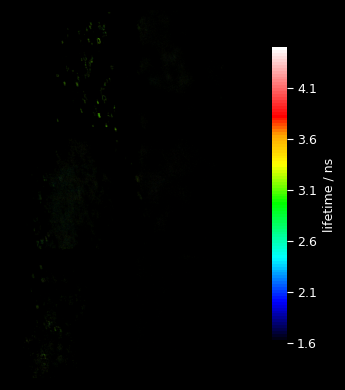

In [15]:
saveLTimg = os.path.join(newFolder, FName)
# limits    = np.asarray(limits, dtype=float) # only needed if run on loop (get the first limits value, then reuse for consistent scaling across images)
limits    = np.array([np.nan, np.nan])
if np.all(np.isnan(limits)):
    ind = tag < threshold
    if not np.any(~ind):
        ind = tag < 1
    tim_auto = tav.copy()
    tim_auto[ind] = 0
    hi1, lo1 = uplowthresh(tim_auto, 0.95, 0.05)
    limits = np.array([lo1, hi1])
    print(f'Auto limits: [{limits[0]:.3f}, {limits[1]:.3f}] ns')

LTImg, Bar = FastFLIM_mod_AT0(saveLTimg, tag, tav, threshold, limits)

## Step 11: Phasor — z-projected, IRF corrected
Combines the full z-stack photon budget for a denser, lower-noise phasor:
1. **Z-projection** — accumulates all z-plane TCSPC arrays into one `(ny, nx, nbin)` image using the same `shift_data` alignment as the rest of the pipeline.
2. **G/S computation** — DFT at the laser repetition frequency with optional `szBin` spatial binning; no uncorrected phasor plot is shown.
3. **IRF reference correction** — maps the IRF phasor to `(G=1, S=0)`, applies the same modulation/phase factors to the sample. Results in `G_corr` / `S_corr`; corrected plot saved as `*_Phas_corr.png`.

`G_ref` / `S_ref` produced here are also consumed by the per-cell phasor cell (Step 15).

IRF phasor:  G_ref = 0.9382,  S_ref = -0.0956
Accumulating z-projected TCSPC (18 planes)... done.
G raw : [0.000, 0.973]  S raw : [0.012, 0.929]  (98051 valid pixels after 3x3 binning)
Ref correction:  M_cor = 1.0604,  phi_cor = 5.82 deg
G corr: [-0.089, 1.009]  S corr: [0.022, 0.991]
tau_phi: [0.279, 76657.445] ns


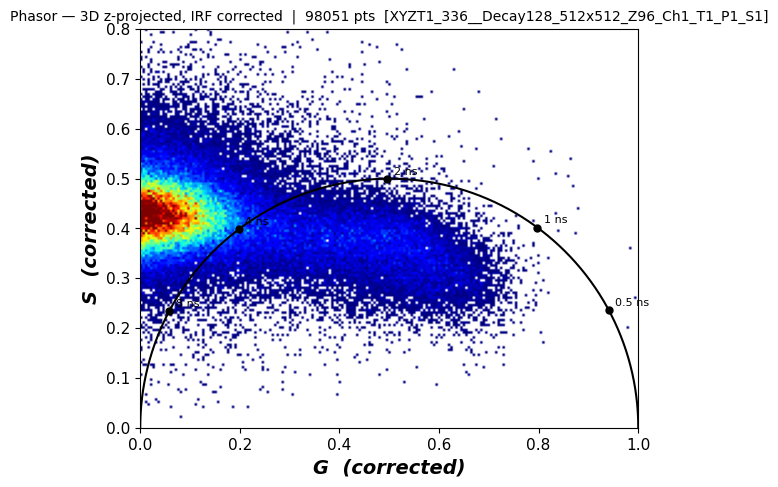

Saved: D:\Peredox_FLIM\20261029_Peredox_336_awake\XYZT1_336__Decay128_512x512_Z96_Ch1_T1_P1_S1\stitched\20261030_1212_FLIM_Analysis\XYZT1_336__Decay128_512x512_Z96_Ch1_T1_P1_S1_Phas_corr.png


In [16]:
freq_mhz = 1000.0 / Tcycle
tau_p    = (np.arange(1, nbin + 1) - 0.5) * dt

try:
    # ── IRF reference phasor ──────────────────────────────────────────────────
    _ph_irf = np.dot(tau_p, IRF2) / IRF2.sum()
    _T_irf  = 2.0 * np.pi * (tau_p - _ph_irf) / Tcycle
    _w_irf  = IRF2 / IRF2.sum()
    G_ref   = np.array([[float(np.dot(np.cos(_T_irf), _w_irf))]])
    S_ref   = np.array([[float(np.dot(np.sin(_T_irf), _w_irf))]])
    print(f'IRF phasor:  G_ref = {G_ref[0,0]:.4f},  S_ref = {S_ref[0,0]:.4f}')

    # ── accumulate z-projected TCSPC (one plane at a time) ───────────────────
    print(f'Accumulating z-projected TCSPC ({n_planes} planes)...', end=' ', flush=True)
    _tcspc_proj = np.zeros((nx, ny, nbin), dtype=float)
    for _path in data_paths:
        _DataZ = _to_yxt(tifffile.imread(_path).astype(float), dim_data)
        _tcspc_proj += np.roll(_DataZ, shift_data, axis=2)
    print('done.')

    # ── compute G / S without plot (mirrors Calc_Phasor_Mat internals) ───────
    _D = _tcspc_proj.copy()
    if szBin > 1:
        _nyb = (nx // szBin) * szBin
        _nxb = (ny // szBin) * szBin
        _D   = _D[:_nyb, :_nxb, :]
        _D   = _D.reshape(_nyb // szBin, szBin, _nxb // szBin, szBin, nbin).sum(axis=(1, 3))
    _tag   = _D.sum(axis=2)
    _ph    = np.dot(tau_p, IRF2) / IRF2.sum()
    _T     = 2.0 * np.pi * (tau_p - _ph) / Tcycle
    _T3    = _T[np.newaxis, np.newaxis, :]
    _tag_s = np.where(_tag > 0, _tag, np.nan)
    G      = (np.cos(_T3) * _D).sum(axis=2) / _tag_s
    S      = (np.sin(_T3) * _D).sum(axis=2) / _tag_s
    _bad   = (_tag < threshold) | (G < 0) | (S < 0)
    G[_bad] = np.nan;  S[_bad] = np.nan
    print(f'G raw : [{np.nanmin(G):.3f}, {np.nanmax(G):.3f}]  '
          f'S raw : [{np.nanmin(S):.3f}, {np.nanmax(S):.3f}]  '
          f'({int((~_bad).sum())} valid pixels after {szBin}x{szBin} binning)')

    # ── reference correction ──────────────────────────────────────────────────
    G_corr, S_corr, tau_mod, tau_phi = phasor_ref_correction(
        G, S, G_ref, S_ref, tau_ref_ns=0.0, freq_mhz=freq_mhz)
    print(f'G corr: [{np.nanmin(G_corr):.3f}, {np.nanmax(G_corr):.3f}]  '
          f'S corr: [{np.nanmin(S_corr):.3f}, {np.nanmax(S_corr):.3f}]')
    _vp = tau_phi[np.isfinite(tau_phi)] if tau_phi is not None else np.array([])
    if _vp.size:
        print(f'tau_phi: [{_vp.min():.3f}, {_vp.max():.3f}] ns')

    # ── build corrected phasor density matrix ─────────────────────────────────
    _gv = G_corr.ravel();  _sv = S_corr.ravel()
    _ok = np.isfinite(_gv) & np.isfinite(_sv)
    _gv, _sv = _gv[_ok], _sv[_ok]

    _nbin_p = int(round(1.0 / szPhs)) + 1
    _Xi     = np.round(_gv / szPhs).astype(int)
    _Yi     = np.round(_sv / szPhs).astype(int)
    M_corr  = np.zeros((_nbin_p, _nbin_p))
    _ok2    = (_Xi >= 0) & (_Xi < _nbin_p) & (_Yi >= 0) & (_Yi < _nbin_p)
    np.add.at(M_corr, (_Yi[_ok2], _Xi[_ok2]), 1)

    # ── corrected phasor plot ─────────────────────────────────────────────────
    fig, ax = plt.subplots(figsize=(6, 6))
    fig.patch.set_facecolor('white');  ax.set_facecolor('white')
    if M_corr.max() > 0:
        _vmax_p = np.percentile(M_corr[M_corr > 0], 99)
        _cmap_p = plt.cm.jet.copy();  _cmap_p.set_under('white')
        ax.imshow(np.flipud(M_corr), extent=[0, 1, 0, 1], aspect='equal',
                  cmap=_cmap_p, origin='upper', vmin=1, vmax=_vmax_p)
    _theta = np.linspace(0, np.pi, 400)
    ax.plot(0.5 + 0.5 * np.cos(_theta), 0.5 * np.sin(_theta), '-', color='black', linewidth=1.5)
    _omega = 2.0 * np.pi * freq_mhz * 1e6
    for _tau_tick in [0.5, 1, 2, 4, 8]:
        _wt  = _omega * _tau_tick * 1e-9
        _g_t = 1.0 / (1.0 + _wt ** 2);  _s_t = _wt / (1.0 + _wt ** 2)
        ax.plot(_g_t, _s_t, 'o', color='black', markersize=5, zorder=5)
        ax.annotate(f'{_tau_tick} ns', xy=(_g_t, _s_t), color='black',
                    fontsize=8, xytext=(5, 3), textcoords='offset points')
    ax.set_xlim(0, 1.0);  ax.set_ylim(0, 0.8);  ax.set_aspect('equal')
    ax.set_xlabel('G  (corrected)', fontweight='bold', fontsize=14, fontstyle='italic')
    ax.set_ylabel('S  (corrected)', fontweight='bold', fontsize=14, fontstyle='italic')
    ax.tick_params(labelsize=11)
    ax.set_title(f'Phasor — 3D z-projected, IRF corrected  |  {_ok.sum()} pts  [{FName}]'
                 + (f'\n{meta_str}' if meta_str else ''), fontsize=10)
    plt.tight_layout()
    _fig_phas = os.path.join(newFolder, FName + '_Phas_corr.png')
    plt.savefig(_fig_phas, facecolor='white', bbox_inches='tight')
    # save as svg too: 
    _fig_phas_svg = os.path.join(newFolder, FName + '_Phas_corr.svg')
    plt.savefig(_fig_phas_svg, facecolor='white', bbox_inches='tight')
    plt.show()
    print(f'Saved: {_fig_phas}')

except Exception as _e:
    import traceback;  traceback.print_exc()
    _nbin3 = int(round(1.0 / szPhs)) + 1
    M_corr = np.zeros((_nbin3, _nbin3))
    G = S = G_corr = S_corr = tau_mod = tau_phi = G_ref = S_ref = None
    print(f'Phasor failed: {_e}')

## Step 12: Lifetime summary metrics
Three independent scalar estimates derived from `tav`:
- **Tau_av** (Method 1): mean of PMT-masked pixels where `tav > H/2`
- **Tau_norm** (Method 3): mean photon arrival time in the whole signal area minus H
- **Tau_mask** (Method 4): mean tav after re-applying the PMT mask to the photon data

In [18]:
# Method 1 -- mean tav of PMT-masked pixels where tav > H/2
Tau_1  = tav * maskPMT
valid  = Tau_1[Tau_1 > (H / 2)]
Tau_av = float(np.nanmean(valid)) if valid.size > 0 else np.nan

# Method 3 -- mean photon arrival time across signal area minus H
Tau_norm = float(np.dot(tau, tmp1) / tmp1.sum() - H)

# Method 4 -- tav mean after re-masking photon data with PMT mask
DT_masked = DataTCSPC * maskPMT[:, :, np.newaxis, np.newaxis]
F1        = np.nansum(T * DT_masked, axis=2) / np.nansum(DT_masked, axis=2)
tav2      = np.clip((F1 - H).squeeze(), 0, None)
Tau_mask  = float(np.nanmean(tav2))

print(f'Tau_av   (Method 1 -- PMT mask, tav > H/2):  {Tau_av:.4f} ns')
print(f'Tau_norm (Method 3 -- area mean - H):         {Tau_norm:.4f} ns')
print(f'Tau_mask (Method 4 -- PMT-masked tav mean):   {Tau_mask:.4f} ns')

Tau_av   (Method 1 -- PMT mask, tav > H/2):  3.0890 ns
Tau_norm (Method 3 -- area mean - H):         3.0709 ns
Tau_mask (Method 4 -- PMT-masked tav mean):   3.0413 ns


C:\Users\Andrea\AppData\Local\Temp\ipykernel_64296\2126572900.py:11: RuntimeWarning: invalid value encountered in divide
  F1        = np.nansum(T * DT_masked, axis=2) / np.nansum(DT_masked, axis=2)


## Step 13: Z-stack loop (all planes)
Processes **all planes** in `data_paths` through the full pipeline.
`limits` (colourmap range) are fixed from the middle plane computed in Steps 1–10 above — run those cells first.

**Outputs per plane**
| File | Content |
|------|---------|
| `*_sumTCSPC_stack.tif` | Raw photon-count maps (float32, multi-page) |
| `*_sumTCSPC_filt_norm_stack.tif` | Filtered + normalised intensity (float32, multi-page) |
| `*_mask_stack.tif` | Threshold masks (float32, multi-page) |
| `*_tav_raw_stack.tif` | Per-pixel mean-arrival-time lifetime before bilateral filter |
| `*_tav_filt_stack.tif` | Bilateral-filtered lifetime (NaN = masked) |
| `*_FLIM_RGB_stack.tif` | False-colour RGB volume (uint8, multi-page) |
| `*_z###_LTimg.png` | Per-plane false-colour FLIM image |
| `*_z###_decay.png` | Per-plane aligned decay plot |
| `*_FLIM_limits.csv` | Colourmap limits (lo/hi ns) from middle plane |

Limits  1.6000 – 4.5000 ns  (from z=9)  →  D:\Peredox_FLIM\20261029_Peredox_336_awake\XYZT1_336__Decay128_512x512_Z96_Ch1_T1_P1_S1\stitched\20261030_1212_FLIM_Analysis\XYZT1_336__Decay128_512x512_Z96_Ch1_T1_P1_S1_FLIM_limits.csv
Computing bulk decay for global shift (18 planes)... done.
Bulk peak bin 19  →  shift_bulk = -9  |  H_bulk = 1.3568 ns
18 planes to process

  z=000/17  tav=3.100 ns  XYZT1_336__Decay128_512x512_Z96_Ch1_T1_P1_S1_stitched_Z000.tif
  z=001/17  tav=2.935 ns  XYZT1_336__Decay128_512x512_Z96_Ch1_T1_P1_S1_stitched_Z001.tif
  z=002/17  tav=2.989 ns  XYZT1_336__Decay128_512x512_Z96_Ch1_T1_P1_S1_stitched_Z002.tif
  z=003/17  tav=2.919 ns  XYZT1_336__Decay128_512x512_Z96_Ch1_T1_P1_S1_stitched_Z003.tif
  z=004/17  tav=2.907 ns  XYZT1_336__Decay128_512x512_Z96_Ch1_T1_P1_S1_stitched_Z004.tif
  z=005/17  tav=2.870 ns  XYZT1_336__Decay128_512x512_Z96_Ch1_T1_P1_S1_stitched_Z005.tif
  z=006/17  tav=2.914 ns  XYZT1_336__Decay128_512x512_Z96_Ch1_T1_P1_S1_stitched_Z006.tif
  z=007

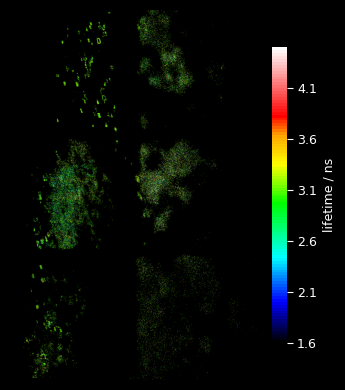

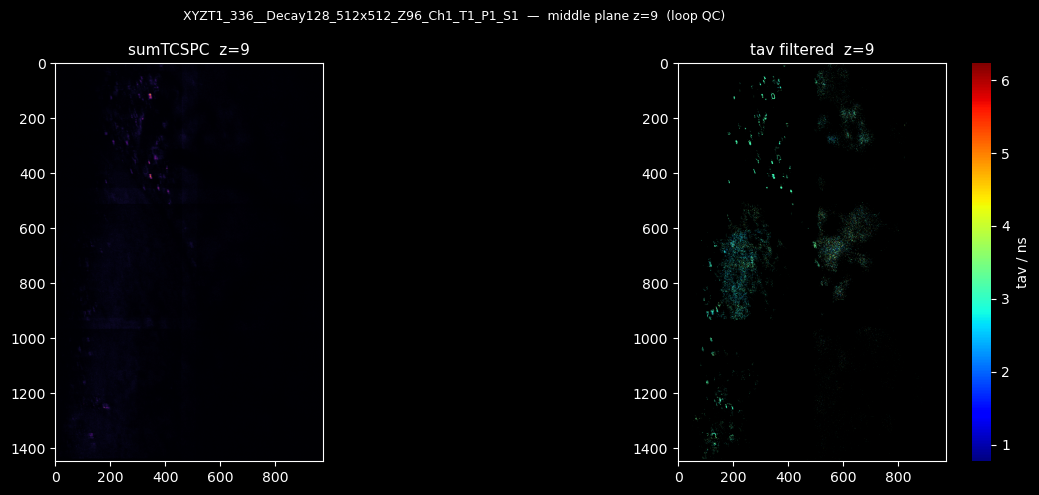

  z=009/17  tav=3.140 ns  XYZT1_336__Decay128_512x512_Z96_Ch1_T1_P1_S1_stitched_Z009.tif
  z=010/17  tav=3.137 ns  XYZT1_336__Decay128_512x512_Z96_Ch1_T1_P1_S1_stitched_Z010.tif
  z=011/17  tav=3.120 ns  XYZT1_336__Decay128_512x512_Z96_Ch1_T1_P1_S1_stitched_Z011.tif
  z=012/17  tav=3.079 ns  XYZT1_336__Decay128_512x512_Z96_Ch1_T1_P1_S1_stitched_Z012.tif
  z=013/17  tav=3.130 ns  XYZT1_336__Decay128_512x512_Z96_Ch1_T1_P1_S1_stitched_Z013.tif
  z=014/17  tav=3.126 ns  XYZT1_336__Decay128_512x512_Z96_Ch1_T1_P1_S1_stitched_Z014.tif
  z=015/17  tav=3.174 ns  XYZT1_336__Decay128_512x512_Z96_Ch1_T1_P1_S1_stitched_Z015.tif
  z=016/17  tav=3.205 ns  XYZT1_336__Decay128_512x512_Z96_Ch1_T1_P1_S1_stitched_Z016.tif
  z=017/17  tav=3.266 ns  XYZT1_336__Decay128_512x512_Z96_Ch1_T1_P1_S1_stitched_Z017.tif

Done.  18 planes processed.
Output folder:  D:\Peredox_FLIM\20261029_Peredox_336_awake\XYZT1_336__Decay128_512x512_Z96_Ch1_T1_P1_S1\stitched\20261030_1212_FLIM_Analysis


In [19]:
importlib.reload(_ffm_module)
from FastFLIM_mod_AT0 import FastFLIM_mod_AT0

# ── output stack paths ─────────────────────────────────────────────────────────
def _sp(tag): return os.path.join(newFolder, f'{FName}_{tag}.tif')
stack_sum      = _sp('sumTCSPC_stack')
stack_norm     = _sp('sumTCSPC_filt_norm_stack')
stack_mask     = _sp('mask_stack')
stack_tav_raw  = _sp('tav_raw_stack')
stack_tav_filt = _sp('tav_filt_stack')
stack_rgb      = _sp('FLIM_RGB_stack')

for _p in [stack_sum, stack_norm, stack_mask, stack_tav_raw, stack_tav_filt, stack_rgb]:
    if os.path.exists(_p): os.remove(_p)

# ── save colourmap limits to CSV ──────────────────────────────────────────────
csv_path = os.path.join(newFolder, f'{FName}_FLIM_limits.csv')
with open(csv_path, 'w', newline='') as _f:
    _w = csv.writer(_f)
    _w.writerow(['lo_ns', 'hi_ns', 'source_plane'])
    _w.writerow([f'{limits[0]:.4f}', f'{limits[1]:.4f}', f'z={mid_idx}'])
print(f'Limits  {limits[0]:.4f} – {limits[1]:.4f} ns  (from z={mid_idx})  →  {csv_path}')

# ── single global shift from bulk fluorescence ────────────────────────────────
# IRF2 was independently aligned to target by cell 5622bfa1 (using its own peak).
# Data is independently aligned to the same target using the bulk fluorescence peak.
# Both arrive at the same reference bin → F - H is unbiased, regardless of when IRF was acquired.
print(f'Computing bulk decay for global shift ({n_planes} planes)...', end=' ', flush=True)
_bulk = np.zeros(nbin, dtype=float)
for _p in data_paths:
    _bulk += _to_yxt(tifffile.imread(_p).astype(float), dim_data).sum(axis=(0, 1))
print('done.')

_peak_bulk = int(np.argmax(_bulk))
shift_bulk = target - _peak_bulk
H_bulk     = float(np.dot(tau, IRF2) / IRF2.sum())   # IRF2 already at target
T_4d       = tau[np.newaxis, np.newaxis, :, np.newaxis]

print(f'Bulk peak bin {_peak_bulk}  →  shift_bulk = {shift_bulk:+d}  |  H_bulk = {H_bulk:.4f} ns')
print(f'{n_planes} planes to process\n')

# ── create output subfolders ─────────────────────────────────────────────────
_zdecay_dir  = os.path.join(newFolder, 'z_decay_plots')
_flimrgb_dir = os.path.join(newFolder, 'FLIM_RGB_planes')
os.makedirs(_zdecay_dir,  exist_ok=True)
os.makedirs(_flimrgb_dir, exist_ok=True)

# ── open all TiffWriters once — keeps planes in the same series ───────────────
_tw_sum  = tifffile.TiffWriter(stack_sum)
_tw_norm = tifffile.TiffWriter(stack_norm)
_tw_mask = tifffile.TiffWriter(stack_mask)
_tw_traw = tifffile.TiffWriter(stack_tav_raw)
_tw_tflt = tifffile.TiffWriter(stack_tav_filt)
_tw_rgb  = tifffile.TiffWriter(stack_rgb)

try:
    # ══════════════════════════════════════════════════════════════════════════
    for z, path in enumerate(data_paths):

        # ── 1. Load plane ──────────────────────────────────────────────────────
        _raw  = tifffile.imread(path).astype(float)
        DataZ = _to_yxt(_raw, dim_data)
        sumZ  = DataZ.sum(axis=2)

        # ── 2. Mask from 3D pre-processed volume ──────────────────────────────
        maskZ_bool = mask3d[z]
        maskZ      = maskZ_bool.astype(float)
        sumZ_norm  = vol_norm_3d[z]

        # ── 3. Apply single global shift (same for all planes) ────────────────
        DataZ = np.roll(DataZ, shift_bulk, axis=2)

        # ── 4. Decay plot — saved, not displayed ──────────────────────────────
        _dec_n = DataZ[maskZ_bool].sum(axis=0).astype(float) if maskZ_bool.any() else DataZ.sum(axis=(0, 1))
        _dec_n = _dec_n / _dec_n.max()
        _irf_n = IRF2 / IRF2.max()
        _fig_d, _ax_d = plt.subplots(figsize=(6, 3.5))
        _ax_d.semilogy(tau, _irf_n, '--k', lw=0.8, label='IRF')
        _ax_d.semilogy(tau, _dec_n, color='steelblue', lw=1.2, label=f'z={z:03d}')
        _ax_d.axvline(tau[target], color='orange', lw=0.8, ls=':')
        _ax_d.set_xlabel('time / ns'); _ax_d.set_ylabel('norm. intensity')
        _ax_d.set_title(f'Aligned decay  [{FName}]  z={z:03d}/{n_planes-1}', fontsize=9)
        _ax_d.set_xlim(0, Tcycle); _ax_d.set_ylim(5e-3, 1.3); _ax_d.legend(fontsize=8)
        _fig_d.tight_layout()
        _fig_d.savefig(os.path.join(_zdecay_dir, f'{FName}_z{z:03d}_decay.png'),
                       dpi=100, bbox_inches='tight')
        plt.close(_fig_d)

        # ── 5. Write intensity / mask planes ──────────────────────────────────
        _tw_sum.write(sumZ.astype(np.float32), contiguous=True)
        _tw_norm.write(sumZ_norm.astype(np.float32), contiguous=True)
        _tw_mask.write(maskZ.astype(np.float32), contiguous=True)

        # ── 6. Apply mask and compute tav ─────────────────────────────────────
        DataZ = (DataZ * maskZ[:, :, np.newaxis]).astype(float)[:, :, :, np.newaxis]
        with np.errstate(invalid='ignore', divide='ignore'):
            _F_z = np.nan_to_num((T_4d * DataZ).sum(axis=2) / DataZ.sum(axis=2))
        tav_z = np.clip((_F_z - H_bulk).squeeze(), 0, None)
        _tw_traw.write(tav_z.astype(np.float32), contiguous=True)

        # ── 7. Bilateral filter ───────────────────────────────────────────────
        _tav_in = tav_z.copy(); _tav_in[~maskZ_bool] = np.nan
        _fill   = float(np.nanmean(_tav_in)) if np.any(np.isfinite(_tav_in)) else 0.0
        tav_filt_z = denoise_bilateral(
            np.where(np.isfinite(_tav_in), _tav_in, _fill),
            sigma_color=sigma_lifetime, sigma_spatial=sigma_spatial, channel_axis=None)
        tav_filt_z[~maskZ_bool] = np.nan
        _tw_tflt.write(tav_filt_z.astype(np.float32), contiguous=True)

        # ── 8. False-colour FLIM image ────────────────────────────────────────
        _png_base = os.path.join(_flimrgb_dir, f'{FName}_z{z:03d}')
        LTImg_z, _ = FastFLIM_mod_AT0(_png_base, sumZ_norm, tav_filt_z, thresh_norm, limits,
                                       show=(z == mid_idx))
        _tw_rgb.write((np.clip(LTImg_z, 0, 1) * 255).astype(np.uint8), photometric='rgb')

        # ── 9. Middle-plane QC visualisation ──────────────────────────────────
        if z == mid_idx:
            _pos_z = tav_filt_z[np.isfinite(tav_filt_z) & (tav_filt_z > 0)]
            _v0 = float(np.percentile(_pos_z,  1)) if _pos_z.size else 0.0
            _v1 = float(np.percentile(_pos_z, 99)) if _pos_z.size else 1.0
            _fig_m, _axes_m = plt.subplots(1, 2, figsize=(12, 5), facecolor='black')
            for _a in _axes_m: _a.set_facecolor('black')
            _axes_m[0].imshow(sumZ, cmap='inferno', aspect='equal', origin='upper')
            _axes_m[0].set_title(f'sumTCSPC  z={z}', color='white', fontsize=11)
            _im_m = _axes_m[1].imshow(tav_filt_z, cmap='jet', aspect='equal', origin='upper',
                                       vmin=_v0, vmax=_v1)
            _axes_m[1].set_title(f'tav filtered  z={z}', color='white', fontsize=11)
            _cb_m = plt.colorbar(_im_m, ax=_axes_m[1], fraction=0.046, pad=0.04)
            _cb_m.set_label('tav / ns', color='white')
            _cb_m.ax.yaxis.set_tick_params(color='white')
            plt.setp(_cb_m.ax.yaxis.get_ticklabels(), color='white')
            _cb_m.outline.set_visible(False)
            for _a in _axes_m:
                _a.tick_params(colors='white')
                for _s in _a.spines.values(): _s.set_edgecolor('white')
            plt.suptitle(f'{FName}  —  middle plane z={z}  (loop QC)', color='white', fontsize=9)
            plt.tight_layout()
            plt.show()

        print(f'  z={z:03d}/{n_planes-1}  tav={np.nanmean(tav_filt_z):.3f} ns  {os.path.basename(path)}')
    # ══════════════════════════════════════════════════════════════════════════

finally:
    for _tw in [_tw_sum, _tw_norm, _tw_mask, _tw_traw, _tw_tflt, _tw_rgb]:
        _tw.close()

print(f'\nDone.  {n_planes} planes processed.')
print(f'Output folder:  {newFolder}')

## Step 14: Per-cell 3D decay fitting
Fits a multi-exponential decay to each Cellpose cell's pooled 3D TCSPC.

**`fit_per_cell` (Step 1, default `False` since 2026-11-23).** At a few hundred to a few thousand photons the per-cell
fits are unstable (Slice3, 700 photons: SD 0.34–0.68 ns between two halves of the same cell, larger than the spread
between cells). With `False`:
- per cell only model-free values: `tav_pooled` (mean photon arrival time of the cell's decay minus the IRF's, as
  Step 17) and the phasor `G_phasor`, `S_phasor` with its phase lifetime `tau_phi` = S / (ω G) and modulation lifetime
  `tau_mod` = √(1/(G² + S²) − 1) / ω (Step 15 plots them). SD at 700 photons: `tav` and `tau_phi` 0.08 ns;
  `tau_mod` depends on the IRF width (Step 5);
- `Fit_decay` runs **once on the pooled decay of all cells** → `*_pooled_fit.csv` (`tau_int` intensity-weighted,
  `tau_amp` amplitude-weighted mean lifetime, components, `fast_frac`, `chi2`) + `*_pooled_fit.png` (fit and
  residuals). `fast_frac` is the photon share of an IRF-shaped component (< 0.05 ns), left out of both means: on the
  2026-11 slices it is ~9% because the stored IRF is broader than the recording's (data rise faster than the IRF
  allows; a fitted IRF width of 0.61–0.67× removes it, chi2 286 → 34). Step 5 now rescales the IRF width when the
  IRF is not from the same session (`irf_width_mode`); an IRF recorded on the imaging day is still best.
  The component shares (`frac1..`) are of all photons in decay components: with `fast_frac` they add up to 1.

The IRF (`IRF2`) comes unchanged from Step 5 (no re-shift, no tail handling here since 2026-11-24). The caches
store its fingerprint `irf_key` and are recomputed when the IRF changes (another file, `irf_tail_ns`,
`irf_width_mode`).

`aw_LT` of the per-cell fits (`True`) is the intensity-weighted mean lifetime: `Fit_decay` returns photons per
component, not amplitudes (see `flim_helpers.pooled_lifetimes`).

**Speed-ups vs original:**
- **Single-pass I/O**: bulk decay and per-cell accumulation are done in one loop over z-planes (was two).
- **Vectorised accumulation**: one-hot matmul + `bincount` replace the inner `for cid in _cids` Python loop.
- **Parallel fitting**: `fit_decays` runs `Fit_decay` in worker processes (`fit_workers`: `None` = all cores but one, `1` = sequential); the results are identical to sequential fits.
- **Two-tier cache**:
  - `*_cell_acc.npz` — accumulated per-cell TCSPC + centroid arrays. Delete to force re-accumulation.
  - `*_per_cell_lifetimes.csv` — fitting results. Delete (keep `.npz`) to re-fit without re-accumulating.

Output names carry `cell_tag` (`''` for Cellpose cells, `_ref<subject>` for reference cells, Step 2b), and the caches are reused only when newer than the label file they were built from (`cells_path`).

`_cell_decays` dict is always reconstructed after loading/computing and is available for Step 15.

In [ ]:
import time as _time
importlib.reload(_ffm_module)
import flim_helpers as _fh_mod; importlib.reload(_fh_mod)
from flim_helpers import Fit_decay, fit_decays, pooled_lifetimes, report_pooled_fit, phasor_lifetimes
from scipy.signal import find_peaks

# ── parameters ───────────────────────────────────────────────────────────────
min_photons        = 500
reRunPerCellDecay  = True   # set True to force re-accumulation (overwrites cache)
fit_workers        = None   # fitting processes: None = all cores but one, 1 = sequential

# ── cache paths ──────────────────────────────────────────────────────────────
_cache_acc  = os.path.join(newFolder, f'{FName}{cell_tag}_cell_acc.npz')
csv_out     = os.path.join(newFolder, f'{FName}{cell_tag}_per_cell_lifetimes.csv')
_fits_path  = os.path.join(newFolder, f'{FName}{cell_tag}_cell_fits.npz')   # decay + model per cell
_pool_csv   = os.path.join(newFolder, f'{FName}{cell_tag}_pooled_fit.csv')  # Fit_decay of the pooled decay of all cells

def _fresh(p):
    # a cache counts only if it is newer than the label volume it was built from (Step 2 / 2b)
    return (os.path.exists(p) and not reRunPerCellDecay
            and os.path.getmtime(p) > os.path.getmtime(cells_path))

_have_acc   = _fresh(_cache_acc)
_have_csv   = _fresh(csv_out)
_have_fits  = _fresh(_fits_path)

# ════════════════════════════════════════════════════════════════════════════
# STAGE 1 — per-cell TCSPC accumulation  (cached in _cache_acc)
#   Set reRunPerCellDecay = True to force re-accumulation.
# ════════════════════════════════════════════════════════════════════════════
if _have_acc:
    print(f'Loading accumulation cache: {os.path.basename(_cache_acc)}')
    _acc        = np.load(_cache_acc)
    bulk_decay  = _acc['bulk_decay']
    _cell_mat   = _acc['cell_decays']
    _cell_vox   = _acc['cell_voxels']
    _cell_z_arr = _acc['cell_z_acc']
    _cell_y_arr = _acc['cell_y_acc']
    _cell_x_arr = _acc['cell_x_acc']
    print(f'Loaded {n_cells} cells,  {int(_cell_vox[1:].sum()):,} voxels total.')
else:
    _ny_p, _nx_p = cp_masks.shape[1], cp_masks.shape[2]
    _ys_flat = np.repeat(np.arange(_ny_p, dtype=float), _nx_p)
    _xs_flat = np.tile  (np.arange(_nx_p, dtype=float), _ny_p)
    _eye_oh  = np.eye(n_cells + 1, dtype=np.float32)

    bulk_decay  = np.zeros(nbin,               dtype=float)
    _cell_mat   = np.zeros((n_cells + 1, nbin), dtype=float)
    _cell_vox   = np.zeros(n_cells + 1,        dtype=float)
    _cell_z_arr = np.zeros(n_cells + 1,        dtype=float)
    _cell_y_arr = np.zeros(n_cells + 1,        dtype=float)
    _cell_x_arr = np.zeros(n_cells + 1,        dtype=float)

    print(f'Accumulating {n_planes} planes (vectorised, single pass)...')
    _t0 = _time.perf_counter()
    for _z, _path in enumerate(data_paths):
        _DataZ     = _to_yxt(tifffile.imread(_path).astype(float), dim_data)
        _mask_flat = cp_masks[_z].ravel()
        _data_flat = np.roll(_DataZ, shift_data, axis=2).reshape(-1, nbin)
        bulk_decay += _data_flat.sum(axis=0)
        _cell_mat  += _eye_oh[_mask_flat].T @ _data_flat
        _bc          = np.bincount(_mask_flat, minlength=n_cells + 1).astype(float)
        _cell_vox   += _bc
        _cell_z_arr += _bc * _z
        _cell_y_arr += np.bincount(_mask_flat, weights=_ys_flat, minlength=n_cells + 1)
        _cell_x_arr += np.bincount(_mask_flat, weights=_xs_flat, minlength=n_cells + 1)
        if (_z + 1) % max(1, n_planes // 10) == 0 or _z == n_planes - 1:
            print(f'  plane {_z + 1}/{n_planes}', end='\r', flush=True)

    print(f'\nDone in {_time.perf_counter() - _t0:.1f} s.')
    np.savez_compressed(_cache_acc,
                        bulk_decay=bulk_decay,  cell_decays=_cell_mat,
                        cell_voxels=_cell_vox,  cell_z_acc=_cell_z_arr,
                        cell_y_acc=_cell_y_arr, cell_x_acc=_cell_x_arr)
    print(f'Saved accumulation cache → {os.path.basename(_cache_acc)}')

# ── Shift bulk decay + all cell decays to 8% target (consistent with Step 5) ──
_peak_bulk       = int(np.argmax(bulk_decay))
_shift_to_target = target - _peak_bulk          # bins to move peak to target
bulk_decay = np.roll(bulk_decay, _shift_to_target)
_cell_mat  = np.roll(_cell_mat,  _shift_to_target, axis=1)
print(f'Bulk peak bin {_peak_bulk}  →  shifted {_shift_to_target:+d} bins  →  target bin {target}  '
      f'(IRF2: at the target since Step 5)')

_cell_decays = {cid: _cell_mat[cid] for cid in range(1, n_cells + 1)}

# ── Auto-detect coherent artifact bump ────────────────────────────────────────
# Some recordings show a small bump a few ns after the peak (an echo of the excitation; the IRF recording
# itself has two, ~3.4 and ~4.9 ns after its peak; Step 5 cuts them from IRF2, irf_tail_ns).
#   bump found -> the fit stops bump_safety_bins before it (t_stop_ns).
#   no bump    -> the whole decay is fitted (t_stop_ns = None).
# (Until 2026-11-23 the no-bump case stopped at the search-window start, ~3.1 ns after the peak. Slice3, 80 cells
#  split into 700-photon halves: per-cell SD of the fitted lifetime 0.51 ns with that stop, 0.34 ns whole decay.)
# Tweak these if the detected bump is wrong (check the shaded region on the plot).
bump_srch_lo_ns    = 3.5   # ← start of search window, ns after peak; raise if still in decay tail
bump_srch_hi_ns    = 7.0   # ← end of search window
bump_safety_bins   = 4     # ← bins to cut before bump centre → t_stop
bump_min_prominence = 0.02  # ← min prominence as fraction of window peak (lower = more sensitive)
_srch_lo = min(nbin - 1, target + max(5, int(round(bump_srch_lo_ns / dt))))
_srch_hi = min(nbin,     target + int(round(bump_srch_hi_ns / dt)))
t_stop_ns = None;  _bump_ns = None
if _srch_hi > _srch_lo + 3:
    _smooth  = np.convolve(bulk_decay, np.ones(5) / 5, mode='same')
    _win     = _smooth[_srch_lo:_srch_hi]
    _win_n   = _win / _win.max() if _win.max() > 0 else _win
    _peaks, _props = find_peaks(_win_n, prominence=bump_min_prominence)
    print(f'Search window: {tau[_srch_lo]:.2f} – {tau[min(_srch_hi-1,nbin-1)]:.2f} ns  '
          f'(bins {_srch_lo}–{_srch_hi})  |  {len(_peaks)} peak(s) found')
    if _peaks.size:
        _best_rel   = _peaks[np.argmax(_win_n[_peaks])]
        _bump_bin   = _srch_lo + int(_best_rel)
        _bump_ns    = float(tau[_bump_bin])
        _t_stop_bin = max(0, _bump_bin - bump_safety_bins)
        t_stop_ns   = float(tau[_t_stop_bin])
        print(f'Coherent bump: bin {_bump_bin}  ({_bump_ns:.3f} ns)  '
              f'→  t_stop = {t_stop_ns:.3f} ns  (bin {_t_stop_bin})')
    else:
        print(f'No bump found (prominence >= {bump_min_prominence}) → fitting the whole decay (t_stop = None). '
              f'If the plot shows a bump, lower bump_min_prominence or adjust bump_srch_lo/hi_ns.')
else:
    print('Bump search window too narrow — fitting the whole decay.')
if _have_fits:   # cached results made with another IRF, t_stop or fit_per_cell, or without the pooled fit, are re-made
    _fz         = np.load(_fits_path)
    _ts_cached  = float(_fz['t_stop_ns'][0])
    _pc_cached  = bool(_fz['per_cell_fit'][0]) if 'per_cell_fit' in _fz.files else True
    _irf_cached = str(_fz['irf_key'][0]) if 'irf_key' in _fz.files else None
    if _irf_cached != irf_key:
        _have_fits = False
        print(f'Cached results were made with another IRF (key {_irf_cached}, now {irf_key}: Step 5) → recomputing.')
    elif not (np.isnan(_ts_cached) if t_stop_ns is None else np.isclose(_ts_cached, t_stop_ns)):
        _have_fits = False
        print(f'Cached fits used t_stop = {_ts_cached:.3f} ns → re-fitting.')
    elif _pc_cached != fit_per_cell or 'pooled_model' not in _fz.files or not os.path.exists(_pool_csv):
        _have_fits = False
        print(f'Cached results: fit_per_cell = {_pc_cached}, pooled fit {"present" if "pooled_model" in _fz.files else "missing"}'
              f' → recomputing with fit_per_cell = {fit_per_cell}.')

# ── QC: bulk decay plot ───────────────────────────────────────────────────────
_bulk_n = bulk_decay / bulk_decay.max()
_irf_n  = IRF2 / IRF2.max()
fig_bulk, ax_bulk = plt.subplots(figsize=(7, 4))
ax_bulk.semilogy(tau, _irf_n,  '--k', lw=0.8, label='IRF (aligned)')
ax_bulk.semilogy(tau, _bulk_n, color='steelblue', lw=1.2, label='Bulk 3D decay')
ax_bulk.axvline(tau[target], color='orange', lw=0.8, ls=':', label=f'peak  bin {target}  (8% target)')
if _srch_hi > _srch_lo + 3:
    ax_bulk.axvspan(tau[_srch_lo], tau[min(_srch_hi - 1, nbin - 1)],
                    alpha=0.08, color='red', label='bump search window')
if _bump_ns is not None:
    ax_bulk.axvline(_bump_ns,  color='orangered', lw=0.8, ls=':', label=f'bump  {_bump_ns:.2f} ns')
if t_stop_ns is not None:
    ax_bulk.axvline(t_stop_ns, color='red',       lw=1.0, ls='--', label=f't_stop  {t_stop_ns:.2f} ns')
else:
    ax_bulk.plot([], [], ' ', label='no bump: whole decay fitted')
ax_bulk.set_xlabel('time / ns');  ax_bulk.set_ylabel('intensity (norm.)')
ax_bulk.set_title(f'Bulk 3D decay  [{FName}]', fontsize=10)
ax_bulk.set_xlim(0, Tcycle);  ax_bulk.set_ylim(5e-3, 1.3);  ax_bulk.legend(fontsize=8)
fig_bulk.tight_layout()
plt.show()

# ════════════════════════════════════════════════════════════════════════════
# STAGE 2 — per-cell Fit_decay  (parallel processes, fit_workers; cached in csv_out + _fits_path)
#   Delete csv_out (and _fits_path) to re-fit without re-accumulating.
# ════════════════════════════════════════════════════════════════════════════
# ── volume centre in physical units (µm) — origin assigned to (0,0,0) ─────────
_vol_cz = (n_planes - 1) / 2.0
_vol_cy = (cp_masks.shape[1] - 1) / 2.0
_vol_cx = (cp_masks.shape[2] - 1) / 2.0
_t_stop_str = f't_stop={t_stop_ns:.3f} ns' if t_stop_ns else 't_stop=None'
_show_cols  = (['cell_id', 'n_voxels', 'n_photons'] + (['aw_LT', 'chi2'] if fit_per_cell else [])
               + ['tav_pooled', 'tau_phi', 'tau_mod'])
_pool_dec   = _cell_mat[1:].sum(axis=0)        # pooled decay of all cells

if _have_acc and _have_csv and _have_fits:
    print(f'Reloading fitting results: {os.path.basename(csv_out)}')
    df_cells = pd.read_csv(csv_out)
    _fits     = np.load(_fits_path)
    _cell_models = _fits['models']   # (n_cells, nbin)
    pooled_fit = dict(pd.read_csv(_pool_csv).iloc[0], model=_fits['pooled_model'])
    if 'dist_from_center_um' not in df_cells.columns:
        df_cells['dist_from_center_um'] = df_cells.apply(
            lambda r: round(float(np.linalg.norm([
                (r['centroid_z'] - _vol_cz) * z_step_um,
                (r['centroid_y'] - _vol_cy) * xy_pixel_um,
                (r['centroid_x'] - _vol_cx) * xy_pixel_um
            ])), 3) if np.isfinite(r['centroid_z']) else np.nan, axis=1)
        df_cells.to_csv(csv_out, index=False)
        print('  dist_from_center_um added to existing CSV.')
    print(df_cells[[c for c in _show_cols if c in df_cells]].to_string(index=False))
else:
    records      = []
    _cell_models = np.full((n_cells, nbin), np.nan)   # row i = cell i+1

    _fit_ids    = [cid for cid in range(1, n_cells + 1) if int(_cell_mat[cid].sum()) >= min_photons]
    _H_irf      = float(np.dot(tau, IRF2) / IRF2.sum())   # IRF mean arrival time = H of Step 8: tav_pooled reference
    _t_fit = _time.perf_counter()
    if fit_per_cell:
        print(f'Fitting {len(_fit_ids)} of {n_cells} cells  (min_photons={min_photons},  {_t_stop_str})...')
        _fit_res = dict(zip(_fit_ids, fit_decays(IRF2, _cell_mat[_fit_ids], Tcycle, dt, t_stop_ns=t_stop_ns,
                                                 n_workers=fit_workers)))
    else:
        _fit_res = {}
        print(f'Per-cell fits off (fit_per_cell = False, Step 1): tav_pooled, phasor, tau_phi and tau_mod for '
              f'{len(_fit_ids)} of {n_cells} cells (>= {min_photons} photons).')

    for cid in range(1, n_cells + 1):
        decay = _cell_mat[cid]
        n_vox = int(_cell_vox[cid])
        n_ph  = int(decay.sum())
        cz = float(_cell_z_arr[cid] / n_vox) if n_vox else np.nan
        cy = float(_cell_y_arr[cid] / n_vox) if n_vox else np.nan
        cx = float(_cell_x_arr[cid] / n_vox) if n_vox else np.nan
        _dz = (cz - _vol_cz) * z_step_um
        _dy = (cy - _vol_cy) * xy_pixel_um
        _dx = (cx - _vol_cx) * xy_pixel_um
        _dist_um = round(float(np.linalg.norm([_dz, _dy, _dx])), 3) if np.isfinite(cz) else np.nan
        rec = dict(cell_id=cid, n_voxels=n_vox, n_photons=n_ph,
                   centroid_z=round(cz, 2), centroid_y=round(cy, 2),
                   centroid_x=round(cx, 2), dist_from_center_um=_dist_um,
                   tav_pooled=round(float(np.dot(tau, decay) / n_ph - _H_irf), 4) if n_ph >= min_photons else np.nan)
        if cid not in _fit_res:
            rec.update(aw_LT=np.nan, chi2=np.nan)
            for i in range(1, 6):
                rec[f'tau{i}'] = np.nan;  rec[f'amp{i}'] = np.nan
            if fit_per_cell:
                print(f'  cell {cid:3d}  SKIP  (n_ph={n_ph})')
        else:
            _t2, _a2, _, _model_curve, _chi2 = _fit_res[cid]
            _cell_models[cid - 1] = _model_curve
            _t2a = np.asarray(_t2).ravel();  _a2a = np.asarray(_a2).ravel()
            _valid = _a2a > 0
            _aw = (float(np.dot(_t2a[_valid], _a2a[_valid]) / _a2a[_valid].sum())
                   if _valid.any() else np.nan)
            rec.update(aw_LT=round(_aw, 4), chi2=round(float(_chi2), 4))
            for i in range(5):
                rec[f'tau{i+1}'] = round(float(_t2a[i]), 4) if i < len(_t2a) else np.nan
                rec[f'amp{i+1}'] = round(float(_a2a[i]), 4) if i < len(_a2a) else np.nan
            print(f'  cell {cid:3d}  vox={n_vox:5d}  ph={n_ph:8,d}  '
                  f'aw_LT={_aw:.3f} ns  chi2={_chi2:.3f}')
        records.append(rec)

    if fit_per_cell:
        print(f'Fitting done in {_time.perf_counter() - _t_fit:.1f} s.')
    df_cells = pd.DataFrame(records)

    # ── phasor per cell: G, S, phase lifetime tau_phi, modulation lifetime tau_mod (IRF reference as Step 11) ──
    _gc, _sc, _tau_phi_c, _tau_mod_c = phasor_lifetimes(_cell_mat[1:], IRF2, dt, Tcycle, min_photons=min_photons)
    df_cells['G_phasor'], df_cells['S_phasor'] = np.round(_gc, 5), np.round(_sc, 5)
    df_cells['tau_phi'],  df_cells['tau_mod']  = np.round(_tau_phi_c, 4), np.round(_tau_mod_c, 4)
    df_cells.to_csv(csv_out, index=False)

    # ── pooled fit: one Fit_decay on the summed decay of all cells ────────────
    pooled_fit = pooled_lifetimes(IRF2, _pool_dec, Tcycle, dt, t_stop_ns=t_stop_ns)
    pd.DataFrame([dict(n_cells=n_cells, n_photons=int(_pool_dec.sum()), t_stop_ns=t_stop_ns if t_stop_ns else np.nan,
                       **{k: v for k, v in pooled_fit.items() if k != 'model'})]).to_csv(_pool_csv, index=False)

    np.savez_compressed(_fits_path,
                        tau_axis     = tau,
                        irf_aligned  = IRF2,
                        irf_key      = np.array([irf_key]),       # Step 5 IRF: the cache is re-made when it changes
                        t_stop_ns    = np.array([t_stop_ns if t_stop_ns else np.nan]),
                        per_cell_fit = np.array([fit_per_cell]),
                        cell_ids     = np.arange(1, n_cells + 1),
                        decays       = _cell_mat[1:],    # (n_cells, nbin) raw TCSPC
                        models       = _cell_models,     # (n_cells, nbin) fitted model (NaN: fit_per_cell = False)
                        pooled_decay = _pool_dec,
                        pooled_model = pooled_fit['model'])
    print(f'Saved: {csv_out}')
    print(f'Saved: {os.path.basename(_pool_csv)}, {os.path.basename(_fits_path)}  '
          f'(keys: tau_axis, irf_aligned, irf_key, t_stop_ns, per_cell_fit, cell_ids, decays, models, pooled_decay, pooled_model)')
    print(df_cells[_show_cols].to_string(index=False))

# ── pooled fit: summary + QC plot (fit and residuals) ─────────────────────────
report_pooled_fit(pooled_fit, tau, _pool_dec, IRF2, Tcycle, t_stop_ns=t_stop_ns,
                  label=f'Pooled fit  [{FName}{cell_tag}]  all {n_cells} cells, {_pool_dec.sum():,.0f} photons, {_t_stop_str}',
                  png_path=_pool_csv.replace('.csv', '.png'))


In [ ]:
# ── Cell to inspect: change this number ──────────────────────────────────────
CELL_NUM = 23          # 1-based cell ID (1 ... n_cells)

# ── Reload flim_helpers so any edits to the module take effect ───────────
import flim_helpers as _fh_mod; importlib.reload(_fh_mod)
from flim_helpers import Fit_decay

# ── Load saved decays + models from disk ───────────────────────────
if not os.path.exists(_fits_path):
    raise FileNotFoundError(
        f"Fits file not found -- run the per-cell fitting cell first.\n{_fits_path}")

_fits       = np.load(_fits_path, allow_pickle=True)
_t          = _fits["tau_axis"]         # (nbin,) time axis in ns
_irf        = _fits["irf_aligned"]      # (nbin,) aligned IRF
_all_decays = _fits["decays"]           # (n_cells, nbin) raw TCSPC
_all_models = _fits["models"]           # (n_cells, nbin) fitted model
_t_stop_val = _fits["t_stop_ns"]
_t_stop_item = _t_stop_val.item()
_t_stop      = float(_t_stop_item) if (_t_stop_item is not None and np.isfinite(float(_t_stop_item))) else None

# ── Reload per-cell CSV for metadata ──────────────────────────────
df_cells = pd.read_csv(csv_out)

# ── Validate requested cell ────────────────────────────────────────
_nc = _all_decays.shape[0]
if not (1 <= CELL_NUM <= _nc):
    raise ValueError(f"CELL_NUM={CELL_NUM} out of range -- dataset has {_nc} cells (1-{_nc})")

_raw = _all_decays[CELL_NUM - 1].astype(float)
_mod = _all_models[CELL_NUM - 1].astype(float)
_row = df_cells[df_cells["cell_id"] == CELL_NUM].iloc[0]
_mod_lbl = "model fit"
if not np.isfinite(_mod).any() and "pooled_model" in _fits.files:   # fit_per_cell = False: pooled fit, scaled
    _mod = _fits["pooled_model"].astype(float) * _raw.sum() / _fits["pooled_model"].sum()
    _mod_lbl = "pooled fit (scaled to this cell)"

# ── Normalise to peak of raw decay ─────────────────────────────────
_pk    = _raw.max() if _raw.max() > 0 else 1.0
_raw_n = _raw / _pk
_mod_n = _mod / _pk
_irf_n = _irf / _irf.max()

# ── Plot ────────────────────────────────────────────────────────────────────
fig, ax = plt.subplots(figsize=(7, 4))
ax.scatter(_t, _raw_n, s=8,  color="steelblue", alpha=0.75, zorder=2, label="raw data")
ax.plot   (_t, _mod_n, "-",  color="tomato",    linewidth=1.8, zorder=3, label=_mod_lbl)
ax.plot   (_t, _irf_n, "--", color="0.45",      linewidth=0.8,           label="IRF (aligned)")
if _t_stop is not None:
    ax.axvline(_t_stop, color="red", linestyle=":", linewidth=1.0,
               label=f"t_stop = {_t_stop:.2f} ns")

ax.set_yscale("log")
ax.set_xlim(_t[0], _t[-1])
ax.set_ylim(5e-3, 1.5)
ax.set_xlabel("time / ns")
ax.set_ylabel("intensity  (norm. to peak)")
ax.set_title(
    f"{FName}  --  cell {CELL_NUM}  |  "
    + (f"aw_LT = {_row['aw_LT']:.3f} ns   chi2 = {_row['chi2']:.2f}   " if np.isfinite(_row['aw_LT'])
       else f"tav {_row.get('tav_pooled', np.nan):.3f}  tau_phi {_row.get('tau_phi', np.nan):.3f}  "
            f"tau_mod {_row.get('tau_mod', np.nan):.3f} ns   ")
    + f"n_photons = {int(_row['n_photons']):,}"
)
ax.legend(fontsize=9, framealpha=0.6)
plt.tight_layout()
plt.show()
# save as SVG 
pathCellDecay = os.path.join(newFolder, f'{FName}{cell_tag}_cell{CELL_NUM}_decay.svg')
fig.savefig(pathCellDecay, format='svg', bbox_inches='tight')


## Step 15: Per-cell phasor (Cellpose-masked, IRF corrected)
Plots the corrected (G, S) phasor coordinate per Cellpose cell, computed from its pooled 3D decay in Step 14
(`flim_helpers.phasor_lifetimes`, the IRF reference of Step 11; columns of the per-cell CSV).

Two scatter panels on the universal semicircle:
- **Left** — dots colored by `aw_LT` of the per-cell fits (`fit_per_cell = True`), else by `tav_pooled`
- **Right** — dots colored by centroid depth (`centroid_z`)

Dot labels show `cell_id`. Back-projection: use `cp_masks == cell_id` to locate those voxels in 3D.
`G_phasor` / `S_phasor` are in the per-cell CSV, with the lifetimes read from the phasor:
`tau_phi` = S / (ω G) (phase lifetime: needs only the phase, i.e. the IRF timing) and `tau_mod` =
√(1 / (G² + S²) − 1) / ω (modulation lifetime: needs the IRF's modulation, i.e. its width). Both equal τ for a
single exponential; for a mixture `tau_phi` < `tau_mod`.

In [ ]:
if 'G_phasor' not in df_cells:
    print('df_cells has no phasor columns: run Step 14 first.')
else:
    # per-cell G / S / tau_phi / tau_mod: computed in Step 14 (flim_helpers.phasor_lifetimes, IRF reference as Step 11)
    _G_corr_c = df_cells['G_phasor'].values.astype(float)
    _S_corr_c = df_cells['S_phasor'].values.astype(float)
    print(f'Per-cell phasor of Step 14 ({os.path.basename(csv_out)}): median tau_phi {df_cells["tau_phi"].median():.3f} ns, '
          f'tau_mod {df_cells["tau_mod"].median():.3f} ns')

    # ── scatter plot: two panels ──────────────────────────────────────────────
    _ok_c   = np.isfinite(_G_corr_c) & np.isfinite(_S_corr_c)
    _g_plot = _G_corr_c[_ok_c]
    _s_plot = _S_corr_c[_ok_c]
    _ids    = df_cells['cell_id'].values[_ok_c]
    _lt_col = ('aw_LT' if fit_per_cell and np.isfinite(df_cells['aw_LT'].values.astype(float)).any()
               else 'tav_pooled')   # per-cell fit lifetime, or the model-free mean arrival time
    _aw     = df_cells[_lt_col].values[_ok_c].astype(float)
    _cz     = df_cells['centroid_z'].values[_ok_c].astype(float)

    _aw_lo, _aw_hi = np.nanpercentile(_aw, [5, 95])  # clamp colormap to 5-95 pct
    _vlims = [(_aw_lo, _aw_hi), (None, None)]        # (vmin, vmax) per panel

    _theta  = np.linspace(0, np.pi, 400)
    _omega  = 2.0 * np.pi * 1e9 / Tcycle
    _max_labels = 10   # show cell-ID annotations only when ≤ this many cells

    fig_cp, axes_cp = plt.subplots(1, 2, figsize=(13, 6))
    fig_cp.patch.set_facecolor('white')
    for _ax, _c, _lbl, _cm, (_vmin, _vmax) in zip(
            axes_cp,
            [_aw, _cz],
            [f'{_lt_col} (ns)', f'centroid z  (0 – {n_planes - 1})'],
            ['plasma', 'viridis'],
            _vlims):
        _ax.set_facecolor('white')
        _ax.plot(0.5 + 0.5 * np.cos(_theta), 0.5 * np.sin(_theta),
                 color='#444444', linewidth=1.2, zorder=2)
        _sc = _ax.scatter(_g_plot, _s_plot, c=_c, cmap=_cm, s=72,
                          edgecolors='none', alpha=0.70, zorder=5,
                          vmin=_vmin, vmax=_vmax)
        _cb = plt.colorbar(_sc, ax=_ax, fraction=0.046, pad=0.04)
        _cb.set_label(_lbl, fontsize=10)
        _cb.ax.tick_params(labelsize=9)
        for _t in [0.5, 1, 2, 4, 8]:
            _wt  = _omega * _t * 1e-9
            _g_t = 1.0 / (1.0 + _wt ** 2);  _s_t = _wt / (1.0 + _wt ** 2)
            _ax.plot(_g_t, _s_t, 'D', color='#777777', markersize=4,
                     markeredgewidth=0, zorder=4)
            _ax.annotate(f'{_t} ns', xy=(_g_t, _s_t), fontsize=8, color='#555555',
                         xytext=(5, 3), textcoords='offset points')
        if len(_ids) <= _max_labels:
            for _cid_lbl, _gv, _sv in zip(_ids, _g_plot, _s_plot):
                _ax.annotate(str(int(_cid_lbl)), xy=(_gv, _sv), fontsize=7,
                             ha='center', va='bottom', xytext=(0, 5),
                             textcoords='offset points', color='#222222')
        _ax.set_xlim(0, 1.0);  _ax.set_ylim(0, 0.55);  _ax.set_aspect('equal')
        _ax.set_xlabel('G  (corrected)', fontweight='bold', fontsize=12, fontstyle='italic')
        _ax.set_ylabel('S  (corrected)', fontweight='bold', fontsize=12, fontstyle='italic')
        _ax.tick_params(labelsize=10)
        _ax.spines[['top', 'right']].set_visible(False)
    axes_cp[0].set_title(f'Per-cell phasor — color: {_lt_col}  [{FName}]', fontsize=10)
    axes_cp[1].set_title(f'Per-cell phasor — color: centroid z  [{FName}]', fontsize=10)
    plt.suptitle(f'{int(_ok_c.sum())} cells with ≥ {min_photons} photons'
                 + (f'   (labels suppressed, n > {_max_labels})' if len(_ids) > _max_labels else ''),
                 fontsize=9, y=1.01)
    plt.tight_layout()
    _fig_cp_phas = os.path.join(newFolder, FName + cell_tag + '_per_cell_phasor.png')
    plt.savefig(_fig_cp_phas, facecolor='white', bbox_inches='tight', dpi=150)
    plt.savefig(_fig_cp_phas.replace('.png', '.svg'), facecolor='white', bbox_inches='tight')
    plt.show()
    print(f'Saved: {_fig_cp_phas}  +  .svg')

## Step 16: Per-cell tav statistics (Cellpose-masked, bilateral-filtered)
Computes per-cell lifetime statistics from the bilateral-filtered `tav_filt_stack.tif` produced by Step 13.

For each Cellpose cell, **valid pixels** are those that are finite and positive within the cell mask.
Reported per cell: `n_valid_px`, `mean_tav`, `std_tav`, `median_tav`, `p25_tav`, `p75_tav`, `iqr_tav`.

Saved to `*_per_cell_tav.csv`. Run Step 13 first.

In [ ]:
# ── output path ──────────────────────────────────────────────────────────────
_tav_csv_out = os.path.join(newFolder, f'{FName}{cell_tag}_per_cell_tav.csv')

if not os.path.exists(stack_tav_filt):
    print(f'ERROR: {os.path.basename(stack_tav_filt)} not found — run Step 13 first.')
else:
    # ── load full filtered-tav stack ──────────────────────────────────────────
    # tifffile writes each plane as a separate series when contiguous=True is
    # omitted — imread then returns only the first page.  Read all pages explicitly.
    with tifffile.TiffFile(stack_tav_filt) as _tf:
        _tav_stack = np.stack([p.asarray() for p in _tf.pages]).astype(float)
    if _tav_stack.ndim == 2:
        _tav_stack = _tav_stack[np.newaxis]
    _nz = _tav_stack.shape[0]
    print(f'Loaded tav_filt_stack: {_nz} planes, shape {_tav_stack.shape}')

    # ── accumulate per-cell tav pixel lists ──────────────────────────────────
    _cell_vals = {cid: [] for cid in range(1, n_cells + 1)}

    for _z in range(_nz):
        _tav_z  = _tav_stack[_z]                         # (Y, X)
        _mask_z = cp_masks[_z]                           # (Y, X) int cell IDs
        _valid  = np.isfinite(_tav_z) & (_tav_z > 0)
        _cids_v = _mask_z[_valid]
        _tav_v  = _tav_z[_valid]
        # group by cell ID without an inner Python loop
        _sort_i = np.argsort(_cids_v, kind='stable')
        _cids_s = _cids_v[_sort_i]
        _tav_s  = _tav_v[_sort_i]
        _uniq, _cnts = np.unique(_cids_s, return_counts=True)
        for _cid, _chunk in zip(_uniq, np.split(_tav_s, np.cumsum(_cnts)[:-1])):
            if 1 <= _cid <= n_cells:
                _cell_vals[int(_cid)].append(_chunk)

    # ── compute statistics ────────────────────────────────────────────────────
    _records = []
    for cid in range(1, n_cells + 1):
        _chunks = _cell_vals[cid]
        if _chunks:
            _arr = np.concatenate(_chunks)
            _p25, _p75 = np.percentile(_arr, [25, 75])
            _records.append(dict(
                cell_id    = cid,
                n_valid_px = len(_arr),
                mean_tav   = round(float(np.mean(_arr)),   4),
                std_tav    = round(float(np.std(_arr)),    4),
                median_tav = round(float(np.median(_arr)), 4),
                p25_tav    = round(float(_p25),            4),
                p75_tav    = round(float(_p75),            4),
                iqr_tav    = round(float(_p75 - _p25),     4),
            ))
        else:
            _records.append(dict(
                cell_id=cid, n_valid_px=0,
                mean_tav=np.nan, std_tav=np.nan, median_tav=np.nan,
                p25_tav=np.nan, p75_tav=np.nan, iqr_tav=np.nan,
            ))

    df_tav = pd.DataFrame(_records)
    df_tav.to_csv(_tav_csv_out, index=False)

    _n_ok = (df_tav.n_valid_px > 0).sum()
    print(f'Saved → {_tav_csv_out}')
    print(f'{_n_ok} / {n_cells} cells have valid tav pixels.')
    print(df_tav[['cell_id', 'n_valid_px', 'mean_tav', 'std_tav', 'median_tav', 'iqr_tav']].to_string(index=False))


---
## Retired / Reference cells
The cells below are **not part of the standard analysis** — they are kept as reference only.
They are all-commented or reference variables from disabled steps.
Do not run them in a fresh session without adapting the variable names.

### [Retired] Bin alignment
Not needed for the current instrument (`nbin_data == Ix`). Re-enable if IRF and data have mismatched bin counts.

In [ ]:
# ── Bin alignment -- not needed for new instrument (nbin_data == Ix assumed) ──
# nbin_data = DataTCSPC.shape[2]
# nbin      = min(nbin_data, Ix)
#
# if nbin < Ix:
#     nrep = int(Ix // nbin)
#     IRF2 = IRF2[:nbin * nrep].reshape(nrep, nbin).mean(axis=0)
#     print(f'IRF averaged: {Ix} -> {nbin} bins  (nrep={nrep})')
# else:
#     nbin   = Ix
#     nx_d, ny_d = DataTCSPC.shape[0], DataTCSPC.shape[1]
#     nrep   = int(nbin_data // nbin)
#     DataTCSPC = DataTCSPC[:, :, :nbin * nrep]
#     DataTCSPC = DataTCSPC.reshape(nx_d, ny_d, nrep, nbin).swapaxes(2, 3)
#     print(f'Data reshaped: {nbin_data} -> ({nbin} bins x {nrep} reps)')
#
# print(f'nbin = {nbin},  DataTCSPC shape = {DataTCSPC.shape}')

### [Retired] Manual IRF peak alignment
Replaced by the peak realignment cell (Step 5). Kept as reference for the alignment logic.

In [ ]:
# ── IRF-to-data peak alignment (replaced by realignment cell -- kept for reference)
# xs1 = int(np.argmax(irf))
# xs2 = int(np.argmax(tmp))
# if xs1 > xs2:
#     shift = xs1 - xs2
#     irf   = np.concatenate([irf[shift:],   np.zeros(shift)])
#     IRF2  = np.concatenate([IRF2[shift:],  np.zeros(shift)])
#     print(f'IRF shifted left by {shift} bins')
# elif xs1 < xs2:
#     shift = xs2 - xs1
#     irf   = np.concatenate([np.zeros(shift), irf[:-shift]])
#     IRF2  = np.concatenate([np.zeros(shift), IRF2[:-shift]])
#     print(f'IRF shifted right by {shift} bins')
# else:
#     print('Peaks already aligned')
#
# fig_lt, ax_lt = plt.subplots(figsize=(7, 4))
# ax_lt.semilogy(tau, irf, '--k', linewidth=0.5, label='IRF')
# ax_lt.semilogy(tau, tmp, ':o', markersize=4, markerfacecolor='b', color='b', label='Data')
# ax_lt.set_ylabel('signal / a.u.')
# ax_lt.set_xlabel('time / ns')
# ax_lt.set_xlim(0, np.ceil(Tcycle))
# ax_lt.set_ylim(5e-3, 1.2)
# ax_lt.legend()
# fig_lt.suptitle(f'LT Data & IRF  {FName}')
# plt.tight_layout()
# plt.show()

### [Retired] Single-plane Fit_decay on middle-plane decay
Fits `Fit_decay` on the spatially-averaged middle-plane decay `tmp1`. Superseded by the per-cell 3D fitting (Step 14). Re-enable and adapt variable names if a single-plane bulk fit is needed.

In [ ]:
# tau2, amp2, off2, _, chi2_2, model2 = Fit_decay(IRF2, tmp1, Tcycle, dt)
#
# # amplitude-weighted lifetime
# valid_mask = amp2 > 0
# aw_LT2 = (float(np.dot(tau2[valid_mask], amp2[valid_mask]) / amp2[valid_mask].sum())
#           if valid_mask.any() and amp2[valid_mask].sum() != 0 else np.nan)
#
# # cap to 5 components for storage
# tau2     = np.asarray(tau2).ravel()[:5]
# amp2     = np.asarray(amp2).ravel()[:5]
# tau_tmp2 = np.zeros(5); tau_tmp2[:len(tau2)] = tau2
# amp_tmp2 = np.zeros(5); amp_tmp2[:len(amp2)] = amp2
#
# print(f'Fit_decay:  chi2 = {chi2_2:.4f},  aw_LT = {aw_LT2:.4f} ns')
# for i, (t_, a_) in enumerate(zip(tau2, amp2)):
#     if a_ > 0:
#         print(f'  Component {i+1}: tau = {t_:.4f} ns,  amp = {a_:.4f}')

### [Retired] Save and collect results
Collects per-session lifetime scalars and saves the middle-plane LT figure. References `fig_lt`, `model2`, `tau_tmp2`, `amp_tmp2`, `aw_LT2`, `chi2_2` — all from the retired steps above.

In [ ]:
# fig_name1 = os.path.join(newFolder, FName + '_LT.png')
# fig_lt.savefig(fig_name1)
# print(f'LT figure saved: {fig_name1}')
#
# Dcays1   = {'ns': tau, 'irf_counts': IRF2}
# Dcays2   = {'tmp1': tmp1, 'model': model2}
# lifetime = {
#     'Tau_av':   Tau_av,
#     'Tau_mask': Tau_mask,
#     'Tau_norm': Tau_norm,
#     'tau_tmp2': tau_tmp2,
#     'amp_tmp2': amp_tmp2,
#     'aw_LT2':   aw_LT2,
#     'chi2':     chi2_2,
# }
# print()
# print('=== Lifetime summary ===')
# for k, v in lifetime.items():
#     print(f'  {k:12s}: {v}')